# Hallucination-Aware Hybrid RAG with Retrieval Transparency Score (RTS v2)
**CSD358 — Information Retrieval · Final Project · Shiv Nadar University**
**Dataset:** BEIR SciFact (+ original SciFact claim labels) · **Runtime:** Google Colab, T4 GPU

This single notebook contains the entire project. It runs top to bottom with **Runtime → Run all**.
Every slow result (embeddings, retrieval runs, LLM outputs, scores) is cached in
`MyDrive/CSD358_IR_Final/`, so a re-run (or a reconnect after Colab drops) takes minutes.

| Part | Content | Status |
|---|---|---|
| 0 | Environment + shared IR library (preprocessing, inverted index, TF-IDF, BM25, dense, RRF, metrics) | ✅ |
| 1 | Data (BEIR SciFact + SciFact labels), mid-term reproduction, corrected baseline | ✅ |
| 2 | Retrieval upgrades: full-abstract dense, train-split tuning, query likelihood, RM3 PRF, cross-encoder re-ranking, significance tests | ✅ |
| 3 | Generative claim verification with cited evidence (local LLM) | ✅ |
| 4 | RTS v2: span attribution + semantic similarity + NLI with contradiction penalty + citation check | ✅ |
| 5 | Evaluation: hallucination detection, human labels, claim verification vs SciFact paper, selective answering, ablations, NFCorpus + FiQA generalisation | ✅ |
| 6 | Interactive demo (Gradio): live verification with RTS v2, hallucination injection, Search lab, results | ✅ |

**Evaluation protocol:** every parameter is tuned on the BEIR SciFact **train** split; the 300 **test**
queries are used only for final evaluation, so there is no leakage.

# Part 0 — Environment and shared IR library

## 0.1 Environment: Google Drive, packages, GPU, seeds

In [1]:
# ============================================================
# 0.1 ENVIRONMENT SETUP
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import os, sys, random, time, pickle
ROOT = '/content/drive/MyDrive/CSD358_IR_Final'
DIRS = {k: f'{ROOT}/{k}' for k in ['data', 'cache', 'runs', 'results', 'figures']}
for p in DIRS.values():
    os.makedirs(p, exist_ok=True)

!pip -q install rank_bm25 faiss-cpu pytrec_eval-terrier

import nltk
for pkg in ['punkt', 'punkt_tab', 'stopwords']:
    nltk.download(pkg, quiet=True)

import numpy as np, pandas as pd, torch
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device :', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE == 'cuda'
      else 'NO GPU — Runtime → Change runtime type → T4 GPU')
print('torch  :', torch.__version__)
print('Project folder on Drive:', ROOT)

Mounted at /content/drive
Device : cpu | NO GPU — Runtime → Change runtime type → T4 GPU
torch  : 2.14.1+cpu
Project folder on Drive: /content/drive/MyDrive/CSD358_IR_Final


## 0.2 Shared IR library
The building blocks used by every part. They are written from scratch where it matters for the course
(inverted index, TF-IDF weighting, BM25, RRF, all metrics), and only call libraries for neural encoders and FAISS.

In [2]:
# ============================================================
# 0.2 LIBRARY IMPORTS
# ============================================================
import heapq
import json
import math
import os
import re
from collections import Counter, defaultdict
from functools import lru_cache

import numpy as np

### 0.3 Preprocessing

In [3]:
# ============================================================
# 0.3 PREPROCESSING
# Preprocessing - identical to the mid-term notebook (Cell 5)
#    case folding -> strip non-alphabetic -> word_tokenize -> stopwords,
#    len > 1 -> Porter stemming
# =============================================================================
_NON_ALPHA = re.compile(r"[^a-z\s]")
_STOPWORDS = None
_STEMMER = None


def _nlp():
    global _STOPWORDS, _STEMMER
    if _STOPWORDS is None:
        from nltk.corpus import stopwords
        from nltk.stem import PorterStemmer
        _STOPWORDS = frozenset(stopwords.words("english"))
        _STEMMER = PorterStemmer()
    return _STOPWORDS, _STEMMER


@lru_cache(maxsize=500_000)
def _stem(tok: str) -> str:
    return _nlp()[1].stem(tok)


def preprocess(text: str, stem: bool = True) -> list:
    from nltk.tokenize import word_tokenize
    stop, _ = _nlp()
    text = _NON_ALPHA.sub(" ", (text or "").lower())
    toks = [t for t in word_tokenize(text) if t not in stop and len(t) > 1]
    return [_stem(t) for t in toks] if stem else toks


def preprocess_corpus(corpus: dict) -> dict:
    """{doc_id: {'title','text'}} -> {doc_id: {'title_tokens','body_tokens','all_tokens'}}"""
    out = {}
    for d, doc in corpus.items():
        tt, bt = preprocess(doc["title"]), preprocess(doc["text"])
        out[d] = {"title_tokens": tt, "body_tokens": bt, "all_tokens": tt + bt}
    return out

### 0.4 Data I/O helpers

In [4]:
# ============================================================
# 0.4 DATA I/O HELPERS
# Small I/O helpers + project data loader
# =============================================================================
def save_json(obj, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f)


def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)


def read_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def write_jsonl(rows, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r) + "\n")


def read_qrels_tsv(path) -> dict:
    qrels = defaultdict(dict)
    with open(path, encoding="utf-8") as f:
        next(f)  # header: query-id  corpus-id  score
        for line in f:
            q, d, s = line.rstrip("\n").split("\t")
            qrels[str(q)][str(d)] = int(s)
    return dict(qrels)


def write_qrels_tsv(qrels: dict, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        f.write("query-id\tcorpus-id\tscore\n")
        for q in qrels:
            for d, s in qrels[q].items():
                f.write(f"{q}\t{d}\t{s}\n")


def load_project_data(data_dir: str) -> dict:
    """Load everything Cell 4 saved to Drive (BEIR format + gold claim labels)."""
    beir = os.path.join(data_dir, "beir_scifact")
    corpus = {r["_id"]: {"title": r["title"], "text": r["text"]}
              for r in read_jsonl(os.path.join(beir, "corpus.jsonl"))}
    queries = {r["_id"]: r["text"] for r in read_jsonl(os.path.join(beir, "queries.jsonl"))}
    data = {
        "corpus": corpus,
        "queries": queries,
        "qrels_train": read_qrels_tsv(os.path.join(beir, "qrels", "train.tsv")),
        "qrels_test": read_qrels_tsv(os.path.join(beir, "qrels", "test.tsv")),
    }
    gold = os.path.join(data_dir, "claims_gold.json")
    data["claims_gold"] = load_json(gold) if os.path.exists(gold) else None
    return data


def claim_label(claim: dict) -> str:
    """Original SciFact claim -> SUPPORT / CONTRADICT / NEI (majority over evidence sets)."""
    labels = [ev["label"] for evs in claim.get("evidence", {}).values() for ev in evs]
    if not labels:
        return "NEI"
    return Counter(labels).most_common(1)[0][0]

### 0.5 Sparse retrieval: inverted index, TF-IDF (lnc/ltc + zones), BM25

In [5]:
# ============================================================
# 0.5 SPARSE RETRIEVAL: INVERTED INDEX, TF-IDF (LNC/LTC + ZONES), BM25
# Sparse retrieval - inverted index built from scratch
# =============================================================================
class SparseIndex:
    """
    Zone-aware inverted index:  term -> {doc_id: tf}
    Keeps per-zone term frequencies so the zone weights can be re-tuned
    without re-tokenising the corpus.
    """

    def __init__(self, processed: dict):
        self.doc_ids = list(processed.keys())
        self.N = len(self.doc_ids)
        self.title_tf, self.body_tf, self.doc_len = {}, {}, {}
        self.postings = defaultdict(dict)
        for d, p in processed.items():
            ttf, btf = Counter(p["title_tokens"]), Counter(p["body_tokens"])
            self.title_tf[d], self.body_tf[d] = ttf, btf
            self.doc_len[d] = len(p["title_tokens"]) + len(p["body_tokens"])
            for t, c in (ttf + btf).items():
                self.postings[t][d] = c
        self.postings = dict(self.postings)
        self.df = {t: len(p) for t, p in self.postings.items()}
        self.idf = {t: math.log(self.N / df) for t, df in self.df.items()}   # log(N/df)
        self.avgdl = sum(self.doc_len.values()) / self.N
        self.cf = {t: sum(p.values()) for t, p in self.postings.items()}     # collection freq
        self.total_tokens = sum(self.doc_len.values())
        self._vec_cache = {}

    def stats(self) -> dict:
        return {
            "documents": self.N,
            "vocabulary": len(self.postings),
            "avg_postings_per_term": round(sum(self.df.values()) / len(self.df), 1),
            "singleton_terms": sum(1 for v in self.df.values() if v == 1),
            "avg_doc_len": round(self.avgdl, 1),
        }

    # ---------------- TF-IDF ----------------
    def tfidf_vectors(self, w_title=2.0, w_body=1.0, doc_idf=True) -> dict:
        """
        Document vectors with zone-weighted log-TF.
            zone_tf(t,d) = w_title * tf_title(t,d) + w_body * tf_body(t,d)
            w(t,d)       = (1 + log zone_tf) * [idf(t) if doc_idf else 1]
            then cosine (L2) normalisation.
        doc_idf=True  -> 'ltc' documents (what the mid-term code actually ran)
        doc_idf=False -> 'lnc' documents (what the mid-term comments described)
        w_title = w_body = 1 -> no zone weighting (plain TF over title+body).
        Weights must be >= 1 so that zone_tf >= 1 and the log-TF stays >= 1.
        """
        assert w_title >= 1 and w_body >= 1, "keep zone weights >= 1 (log-TF >= 1)"
        key = (float(w_title), float(w_body), bool(doc_idf))
        if key in self._vec_cache:
            return self._vec_cache[key]
        vecs = {}
        for d in self.doc_ids:
            zw = defaultdict(float)
            for t, c in self.title_tf[d].items():
                zw[t] += w_title * c
            for t, c in self.body_tf[d].items():
                zw[t] += w_body * c
            v = {t: (1.0 + math.log(w)) * (self.idf[t] if doc_idf else 1.0)
                 for t, w in zw.items()}
            norm = math.sqrt(sum(x * x for x in v.values()))
            vecs[d] = {t: x / norm for t, x in v.items()} if norm > 0 else v
        self._vec_cache[key] = vecs
        return vecs

    def tfidf_search(self, q_tokens: list, doc_vecs: dict, top_k=1000) -> list:
        """Query = ltc (log-TF x idf, cosine-normalised). Index elimination + heap top-K."""
        if not q_tokens:
            return []
        q = {t: (1.0 + math.log(c)) * self.idf.get(t, 0.0) for t, c in Counter(q_tokens).items()}
        qn = math.sqrt(sum(x * x for x in q.values()))
        if qn == 0:
            return []
        scores = defaultdict(float)
        for t, w in q.items():
            if w == 0 or t not in self.postings:
                continue
            w /= qn
            for d in self.postings[t]:                     # only docs in postings
                scores[d] += w * doc_vecs[d].get(t, 0.0)
        return heapq.nlargest(top_k, scores.items(), key=lambda x: x[1])

    # ---------------- BM25 (from scratch) ----------------
    def bm25_search(self, q_tokens: list, k1=0.9, b=0.4, top_k=1000) -> list:
        """
        Okapi BM25 with the Lucene/Anserini non-negative IDF:
            idf(t) = log(1 + (N - df + 0.5) / (df + 0.5))
            score(q,d) = sum_t idf(t) * tf*(k1+1) / (tf + k1*(1 - b + b*|d|/avgdl))
        Repeated query terms are counted once per occurrence (as rank_bm25 does).
        """
        scores = defaultdict(float)
        for t in q_tokens:
            post = self.postings.get(t)
            if not post:
                continue
            n = len(post)
            idf = math.log(1.0 + (self.N - n + 0.5) / (n + 0.5))
            for d, tf in post.items():
                denom = tf + k1 * (1.0 - b + b * self.doc_len[d] / self.avgdl)
                scores[d] += idf * tf * (k1 + 1.0) / denom
        return heapq.nlargest(top_k, scores.items(), key=lambda x: x[1])


class MidtermBM25:
    """rank_bm25.BM25Okapi exactly as in the mid-term (used for reproduction only)."""

    def __init__(self, processed: dict, k1=1.5, b=0.75):
        from rank_bm25 import BM25Okapi
        self.doc_ids = list(processed.keys())
        self.bm25 = BM25Okapi([processed[d]["all_tokens"] for d in self.doc_ids], k1=k1, b=b)

    def search(self, q_tokens: list, top_k=1000) -> list:
        s = self.bm25.get_scores(q_tokens)
        idx = heapq.nlargest(top_k, range(len(s)), key=lambda i: s[i])
        return [(self.doc_ids[i], float(s[i])) for i in idx]

### 0.6 Dense retrieval: SBERT + FAISS

In [6]:
# ============================================================
# 0.6 DENSE RETRIEVAL: SBERT + FAISS
# Dense retrieval - SBERT + FAISS (exact inner product on L2-normalised vectors)
# =============================================================================
def encode_cached(model, texts: list, path: str, batch_size=64) -> np.ndarray:
    """Encode with SBERT once, then reuse the .npy cache on Drive."""
    if os.path.exists(path):
        emb = np.load(path)
        if emb.shape[0] == len(texts):
            return emb
    emb = model.encode(texts, batch_size=batch_size, show_progress_bar=True,
                       convert_to_numpy=True, normalize_embeddings=True).astype("float32")
    os.makedirs(os.path.dirname(path), exist_ok=True)
    np.save(path, emb)
    return emb


class DenseIndex:
    def __init__(self, embeddings: np.ndarray, doc_ids: list):
        import faiss
        self.doc_ids = list(doc_ids)
        self.index = faiss.IndexFlatIP(embeddings.shape[1])
        self.index.add(np.ascontiguousarray(embeddings, dtype="float32"))

    def search(self, query_embs: np.ndarray, top_k=1000) -> list:
        """query_embs: (n_queries, dim), L2-normalised. Returns one ranked list per query."""
        top_k = min(top_k, len(self.doc_ids))
        D, I = self.index.search(np.ascontiguousarray(query_embs, dtype="float32"), top_k)
        return [[(self.doc_ids[i], float(s)) for i, s in zip(row_i, row_d) if i >= 0]
                for row_i, row_d in zip(I, D)]

### 0.7 Rank fusion: weighted RRF

In [7]:
# ============================================================
# 0.7 RANK FUSION: WEIGHTED RRF
# Fusion
# =============================================================================
def rrf(ranked_lists: list, k=60, weights=None, depth=None) -> list:
    """
    Weighted Reciprocal Rank Fusion (Cormack et al., 2009):
        RRF(d) = sum_i  w_i / (k + rank_i(d))
    depth: only the top-`depth` docs of each input list are fused.
    """
    scores = defaultdict(float)
    for i, lst in enumerate(ranked_lists):
        w = 1.0 if weights is None else weights[i]
        if w == 0:
            continue
        for r, (d, _) in enumerate(lst[:depth] if depth else lst, start=1):
            scores[d] += w / (k + r)
    return sorted(scores.items(), key=lambda x: -x[1])

### 0.8 Evaluation metrics (+ trec_eval cross-check)

In [8]:
# ============================================================
# 0.8 EVALUATION METRICS (+ TREC_EVAL CROSS-CHECK)
# Evaluation
# =============================================================================
METRICS = ["MAP", "MAP@10", "MRR", "MRR@10", "NDCG@10", "P@5", "P@10", "R@10", "R@100", "F1@10"]


def _ids(ranked):
    """Accept [(doc, score), ...] or [doc, ...]."""
    if ranked and isinstance(ranked[0], (tuple, list)):
        return [d for d, _ in ranked]
    return list(ranked)


def per_query_metrics(ranked, qrels_q: dict) -> dict:
    ranked = _ids(ranked)
    rel = {d: s for d, s in qrels_q.items() if s > 0}
    R = len(rel)
    hits = [1 if d in rel else 0 for d in ranked]

    def ap(cut=None):
        h, total = 0, 0.0
        for i, x in enumerate(hits[:cut] if cut else hits, 1):
            if x:
                h += 1
                total += h / i
        return total / R

    def rr(cut=None):
        for i, x in enumerate(hits[:cut] if cut else hits, 1):
            if x:
                return 1.0 / i
        return 0.0

    dcg = sum(rel.get(d, 0) / math.log2(i + 1) for i, d in enumerate(ranked[:10], 1))
    ideal = sorted(rel.values(), reverse=True)[:10]
    idcg = sum(g / math.log2(i + 1) for i, g in enumerate(ideal, 1))
    p10, r10 = sum(hits[:10]) / 10, sum(hits[:10]) / R
    return {
        "MAP": ap(), "MAP@10": ap(10), "MRR": rr(), "MRR@10": rr(10),
        "NDCG@10": dcg / idcg if idcg > 0 else 0.0,
        "P@5": sum(hits[:5]) / 5, "P@10": p10,
        "R@10": r10, "R@100": sum(hits[:100]) / R,
        "F1@10": 2 * p10 * r10 / (p10 + r10) if (p10 + r10) > 0 else 0.0,
    }


def evaluate(run: dict, qrels: dict, qids=None):
    """
    run:   {qid: ranked list}   qrels: {qid: {doc_id: rel}}
    Evaluates every judged query with >= 1 relevant doc (missing runs score 0).
    Returns (mean_metrics: dict, per_query: {qid: metrics}).
    """
    qids = qids if qids is not None else [q for q in qrels if any(s > 0 for s in qrels[q].values())]
    per_q = {q: per_query_metrics(run.get(q, []), qrels[q]) for q in qids}
    mean = {m: float(np.mean([per_q[q][m] for q in qids])) for m in METRICS}
    mean["n_queries"] = len(qids)
    return mean, per_q


_PYTREC_MAP = {"MAP": "map", "MRR": "recip_rank", "NDCG@10": "ndcg_cut_10",
               "P@5": "P_5", "P@10": "P_10", "R@10": "recall_10", "R@100": "recall_100"}


def pytrec_crosscheck(run: dict, qrels: dict, ours: dict, tol=1e-6) -> dict:
    """Recompute the overlapping metrics with pytrec_eval (trec_eval) and compare."""
    import pytrec_eval
    qids = [q for q in qrels if any(s > 0 for s in qrels[q].values())]
    # rank-based scores avoid trec_eval re-ordering ties by doc id
    r = {q: {d: float(len(_ids(run.get(q, []))) - i) for i, d in enumerate(_ids(run.get(q, [])))}
         for q in qids}
    r = {q: v if v else {"__none__": 0.0} for q, v in r.items()}
    ev = pytrec_eval.RelevanceEvaluator({q: {d: int(s) for d, s in qrels[q].items()} for q in qids},
                                        {"map", "recip_rank", "ndcg_cut.10", "P.5", "P.10",
                                         "recall.10", "recall.100"})
    res = ev.evaluate(r)
    out = {}
    for ours_name, tname in _PYTREC_MAP.items():
        theirs = float(np.mean([res[q][tname] for q in qids]))
        out[ours_name] = (ours[ours_name], theirs, abs(ours[ours_name] - theirs) <= tol)
    return out


def results_table(rows: dict, metrics=None):
    """rows: {system_name: mean_metrics} -> pandas DataFrame (4 d.p.)."""
    import pandas as pd
    metrics = metrics or METRICS
    return pd.DataFrame({k: {m: v[m] for m in metrics} for k, v in rows.items()}).T.round(4)


def to_id_run(run: dict) -> dict:
    """{qid: [(doc, score)]} -> {qid: [doc]}  (compact for saving)."""
    return {q: _ids(v) for q, v in run.items()}

In [9]:
print('✅ Shared IR library ready')

✅ Shared IR library ready


# Part 1 — Data, mid-term reproduction and corrected baseline
## 1.1 Data: BEIR SciFact + original SciFact claim labels
* **BEIR SciFact** (Thakur et al., 2021): 5,183 abstracts, 1,109 claims, qrels for **train** and **test**.
* **Original SciFact** (Wadden et al., 2020): for every claim, the human label **SUPPORT / CONTRADICT**
  per evidence abstract plus the **rationale sentence indices**. Claims without evidence are **NEI**.
  BEIR removes these labels; Parts 4–5 need them to measure hallucination detection with
  Precision / Recall / Accuracy / F1.
* Everything is saved under `data/` (this folder goes into the submission ZIP).

In [10]:
# ============================================================
# 1.1 DOWNLOAD, SAVE AND ALIGN THE DATASETS
# ============================================================
import io, tarfile, requests
from datasets import load_dataset

BEIR_DIR = f"{DIRS['data']}/beir_scifact"
SF_DIR   = f"{DIRS['data']}/scifact_original"
os.makedirs(f'{BEIR_DIR}/qrels', exist_ok=True); os.makedirs(SF_DIR, exist_ok=True)

# ---------- BEIR SciFact ----------
if not os.path.exists(f'{BEIR_DIR}/corpus.jsonl'):
    cds = load_dataset('BeIR/scifact', 'corpus',  split='corpus')
    qds = load_dataset('BeIR/scifact', 'queries', split='queries')
    write_jsonl([{'_id': str(r['_id']), 'title': r['title'], 'text': r['text']} for r in cds], f'{BEIR_DIR}/corpus.jsonl')
    write_jsonl([{'_id': str(r['_id']), 'text': r['text']} for r in qds], f'{BEIR_DIR}/queries.jsonl')
for split in ['test', 'train']:
    path = f'{BEIR_DIR}/qrels/{split}.tsv'
    if not os.path.exists(path):
        try:
            ds = load_dataset('BeIR/scifact-qrels', split=split)
            q = {}
            for r in ds:
                q.setdefault(str(r['query-id']), {})[str(r['corpus-id'])] = int(r['score'])
            write_qrels_tsv(q, path)
        except Exception as e:
            print(f'⚠️ BEIR {split} qrels not available on HF ({e}); deriving them from SciFact evidence below.')

# ---------- Original SciFact ----------
SF_FILES = ['corpus.jsonl', 'claims_train.jsonl', 'claims_dev.jsonl']

def fetch_scifact_s3():
    url = 'https://scifact.s3-us-west-2.amazonaws.com/release/latest/data.tar.gz'
    r = requests.get(url, timeout=180); r.raise_for_status()
    with tarfile.open(fileobj=io.BytesIO(r.content), mode='r:gz') as tar:
        for m in tar.getmembers():
            name = os.path.basename(m.name)                 # flatten paths = safe extraction
            if m.isfile() and name in SF_FILES + ['claims_test.jsonl']:
                with open(f'{SF_DIR}/{name}', 'wb') as f:
                    f.write(tar.extractfile(m).read())

def fetch_scifact_hf():
    # fallback: Hugging Face parquet conversion of allenai/scifact (one row per evidence set)
    for split, fname in [('train', 'claims_train.jsonl'), ('validation', 'claims_dev.jsonl')]:
        ds = load_dataset('allenai/scifact', 'claims', split=split, revision='refs/convert/parquet')
        cl = {}
        for r in ds:
            c = cl.setdefault(r['id'], {'id': r['id'], 'claim': r['claim'], 'evidence': {},
                                        'cited_doc_ids': list(r['cited_doc_ids'])})
            if r['evidence_doc_id']:
                c['evidence'].setdefault(str(r['evidence_doc_id']), []).append(
                    {'sentences': list(r['evidence_sentences']), 'label': r['evidence_label']})
        write_jsonl(list(cl.values()), f'{SF_DIR}/{fname}')
    cds = load_dataset('allenai/scifact', 'corpus', split='train', revision='refs/convert/parquet')
    write_jsonl([{'doc_id': r['doc_id'], 'title': r['title'], 'abstract': list(r['abstract'])} for r in cds],
                f'{SF_DIR}/corpus.jsonl')

if not all(os.path.exists(f'{SF_DIR}/{f}') for f in SF_FILES):
    try:
        fetch_scifact_s3(); print('SciFact downloaded from the official S3 release')
    except Exception as e:
        print('S3 download failed:', e, '→ trying the Hugging Face mirror')
        fetch_scifact_hf(); print('SciFact downloaded from Hugging Face')

sf_corpus = {str(r['doc_id']): r for r in read_jsonl(f'{SF_DIR}/corpus.jsonl')}
claims = {}
for fname, split in [('claims_train.jsonl', 'train'), ('claims_dev.jsonl', 'dev')]:
    for c in read_jsonl(f'{SF_DIR}/{fname}'):
        c['split'] = split
        claims[str(c['id'])] = c

if not os.path.exists(f'{BEIR_DIR}/qrels/train.tsv'):     # same construction BEIR used
    write_qrels_tsv({q: {d: 1 for d in c['evidence']} for q, c in claims.items()
                     if c['split'] == 'train' and c['evidence']}, f'{BEIR_DIR}/qrels/train.tsv')

data = load_project_data(DIRS['data'])
corpus, queries = data['corpus'], data['queries']
qrels_train, qrels_test = data['qrels_train'], data['qrels_test']

# ---------- Alignment checks ----------
print('\n📊 BEIR SciFact')
print(f'   corpus {len(corpus):,} docs | queries {len(queries):,} | train qrels {len(qrels_train)} queries | test qrels {len(qrels_test)} queries')
print(f'   train/test query overlap: {len(set(qrels_test) & set(qrels_train))} (must be 0)')

print('\n📊 Original SciFact claims')
print(f'   train claims {sum(c["split"]=="train" for c in claims.values())} | dev claims {sum(c["split"]=="dev" for c in claims.values())}')
print(f'   BEIR test queries found in SciFact dev   : {sum(q in claims and claims[q]["split"]=="dev" for q in qrels_test)}/{len(qrels_test)}')
print(f'   BEIR train queries found in SciFact train: {sum(q in claims and claims[q]["split"]=="train" for q in qrels_train)}/{len(qrels_train)}')
match_ev = sum(set(qrels_test[q]) == set(claims[q]['evidence']) for q in qrels_test if q in claims)
match_ci = sum(set(qrels_test[q]) == {str(d) for d in claims[q]['cited_doc_ids']} for q in qrels_test if q in claims)
print(f'   test qrels == evidence docs: {match_ev} | == cited docs: {match_ci}')
print(f'   labels — BEIR test queries: {dict(Counter(claim_label(claims[q]) for q in qrels_test if q in claims))}')
print(f'   labels — all dev claims   : {dict(Counter(claim_label(c) for c in claims.values() if c["split"]=="dev"))}')
print(f'   labels — all train claims : {dict(Counter(claim_label(c) for c in claims.values() if c["split"]=="train"))}')
same_text = sum(' '.join(sf_corpus[d]['abstract']).strip() == corpus[d]['text'].strip() for d in corpus if d in sf_corpus)
print(f'   docs in both corpora: {sum(d in sf_corpus for d in corpus)} | identical text: {same_text}')

# ---------- Gold file for Parts 4–5 ----------
claims_gold = {}
for q, c in claims.items():
    ev = {}
    for d, sets in c['evidence'].items():
        sents = sorted({i for s in sets for i in s['sentences']})
        abstract = sf_corpus.get(d, {}).get('abstract', [])
        ev[d] = {'label': Counter(s['label'] for s in sets).most_common(1)[0][0],
                 'sentences': sents,
                 'rationale_text': [abstract[i] for i in sents if i < len(abstract)]}
    claims_gold[q] = {'claim': c['claim'], 'split': c['split'], 'label': claim_label(c),
                      'evidence': ev, 'cited_doc_ids': [str(d) for d in c.get('cited_doc_ids', [])],
                      'in_beir_test': q in qrels_test, 'in_beir_train': q in qrels_train}
abstract_sentences = {d: v['abstract'] for d, v in sf_corpus.items()}
save_json(claims_gold, f"{DIRS['data']}/claims_gold.json")
save_json(abstract_sentences, f"{DIRS['data']}/abstract_sentences.json")
print('\n✅ Saved data/claims_gold.json and data/abstract_sentences.json')


📊 BEIR SciFact
   corpus 5,183 docs | queries 1,109 | train qrels 809 queries | test qrels 300 queries
   train/test query overlap: 0 (must be 0)

📊 Original SciFact claims
   train claims 809 | dev claims 300
   BEIR test queries found in SciFact dev   : 300/300
   BEIR train queries found in SciFact train: 809/809
   test qrels == evidence docs: 175 | == cited docs: 300
   labels — BEIR test queries: {'NEI': 112, 'SUPPORT': 124, 'CONTRADICT': 64}
   labels — all dev claims   : {'NEI': 112, 'SUPPORT': 124, 'CONTRADICT': 64}
   labels — all train claims : {'NEI': 304, 'CONTRADICT': 173, 'SUPPORT': 332}
   docs in both corpora: 5183 | identical text: 4128

✅ Saved data/claims_gold.json and data/abstract_sentences.json


## 1.2 Preprocessing and inverted index
Same pipeline as the mid-term. The vocabulary should again be **20,865** terms, a check that
preprocessing is identical.

In [11]:
# ============================================================
# 1.2 PREPROCESS CORPUS + QUERIES, BUILD THE INVERTED INDEX
# ============================================================
PROC_PATH = f"{DIRS['cache']}/processed_corpus.pkl"
if os.path.exists(PROC_PATH):
    processed = pickle.load(open(PROC_PATH, 'rb'))
else:
    t0 = time.time()
    processed = preprocess_corpus(corpus)
    pickle.dump(processed, open(PROC_PATH, 'wb'))
    print(f'Preprocessed corpus in {time.time()-t0:.1f}s')

q_tokens  = {q: preprocess(t) for q, t in queries.items()}
index     = SparseIndex(processed)
doc_ids   = list(corpus.keys())
test_qids  = sorted(q for q in qrels_test if q in queries)
train_qids = sorted(q for q in qrels_train if q in queries)
save_json({'test_qids': test_qids, 'train_qids': train_qids}, f"{DIRS['data']}/split_qids.json")

print('✅ Index stats:', index.stats())
print(f'   train queries: {len(train_qids)} (tuning) | test queries: {len(test_qids)} (final evaluation only)')
if index.stats()['vocabulary'] != 20865:
    print('⚠️ Vocabulary differs from the mid-term (20,865) — probably an NLTK version difference')

✅ Index stats: {'documents': 5183, 'vocabulary': 20865, 'avg_postings_per_term': 20.7, 'singleton_terms': 9428, 'avg_doc_len': 138.6}
   train queries: 809 (tuning) | test queries: 300 (final evaluation only)


## 1.3 Exact reproduction of the mid-term results (300 test queries)
Same configuration as the mid-term: zone TF-IDF (w_title = 2, w_body = 1, IDF on documents),
`rank_bm25` BM25Okapi (k1 = 1.5, b = 0.75), MiniLM on `title + ". " + text[:256]`, and RRF (k = 60) over the
top-20 of each list, cut to 10. The mid-term **MAP was computed on the top-10 only**, so it is really
**MAP@10** (and MRR is MRR@10). Dense scores can differ in the 3rd–4th decimal because embeddings are now
computed on GPU instead of CPU.

In [12]:
# ============================================================
# 1.3 REPRODUCE THE MID-TERM BASELINE
# ============================================================
from sentence_transformers import SentenceTransformer

sbert = SentenceTransformer('all-MiniLM-L6-v2', device=DEVICE)
emb_256 = encode_cached(sbert, [corpus[d]['title'] + '. ' + corpus[d]['text'][:256] for d in doc_ids],
                        f"{DIRS['cache']}/emb_minilm_trunc256.npy")
dense_256  = DenseIndex(emb_256, doc_ids)
q_emb_test = sbert.encode([queries[q] for q in test_qids], normalize_embeddings=True, convert_to_numpy=True)

zone_ltc = index.tfidf_vectors(w_title=2.0, w_body=1.0, doc_idf=True)    # what the mid-term code ran
bm25_mt  = MidtermBM25(processed, k1=1.5, b=0.75)

runs_mt = {'Zone TF-IDF': {}, 'BM25': {}, 'Dense SBERT (256)': {}, 'Hybrid RRF': {}}
for q, dl in zip(test_qids, dense_256.search(q_emb_test, top_k=20)):
    tf = index.tfidf_search(q_tokens[q], zone_ltc, top_k=20)
    bm = bm25_mt.search(q_tokens[q], top_k=20)
    runs_mt['Zone TF-IDF'][q], runs_mt['BM25'][q], runs_mt['Dense SBERT (256)'][q] = tf[:10], bm[:10], dl[:10]
    runs_mt['Hybrid RRF'][q] = rrf([bm, tf, dl], k=60)[:10]

REPORTED = {'Zone TF-IDF':       (0.5877, 0.6026, 0.6482),
            'BM25':              (0.6378, 0.6494, 0.6875),
            'Dense SBERT (256)': (0.5349, 0.5468, 0.5856),
            'Hybrid RRF':        (0.6300, 0.6444, 0.6915)}
rows = []
for name, run in runs_mt.items():
    m, _ = evaluate(run, qrels_test, test_qids)
    now, rep = (m['MAP@10'], m['MRR@10'], m['NDCG@10']), REPORTED[name]
    rows.append({'System': name, 'MAP@10 now': now[0], 'MAP mid-term': rep[0],
                 'MRR@10 now': now[1], 'MRR mid-term': rep[1],
                 'NDCG@10 now': now[2], 'NDCG@10 mid-term': rep[2],
                 'max |Δ|': max(abs(a - b) for a, b in zip(now, rep))})
repro = pd.DataFrame(rows).set_index('System').round(4)
print(f'MID-TERM REPRODUCTION — BEIR SciFact test ({len(test_qids)} judged queries)')
display(repro)
print('✅ Mid-term results reproduced' if repro['max |Δ|'].max() < 0.005
      else '⚠️ Differences larger than expected — paste this table to Claude')
repro.to_csv(f"{DIRS['results']}/p1_midterm_reproduction.csv")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

MID-TERM REPRODUCTION — BEIR SciFact test (300 judged queries)


,MAP@10 now,MAP mid-term,MRR@10 now,MRR mid-term,NDCG@10 now,NDCG@10 mid-term,max |Δ|
System,,,,,,,
Zone TF-IDF,0.5877,0.5877,0.6026,0.6026,0.6482,0.6482,0.0
BM25,0.6378,0.6378,0.6494,0.6494,0.6875,0.6875,0.0
Dense SBERT (256),0.5349,0.5349,0.5468,0.5468,0.5856,0.5856,0.0
Hybrid RRF,0.6300,0.6300,0.6444,0.6444,0.6915,0.6915,0.0


✅ Mid-term results reproduced


## 1.4 Corrected baseline: full metric suite, TF-IDF ablation, trec_eval cross-check
* Single retrievers return the **top 1,000** documents (the BEIR / trec_eval convention), so **MAP** and
  **R@100** are meaningful. The mid-term hybrid only fuses top-20 lists (≤ 60 docs); Part 2 replaces it
  with deep, tuned fusion.
* **2 × 2 TF-IDF ablation:** document weighting {lnc, ltc} × {no zones, zones 2:1}. The mid-term system was
  **ltc.ltc + zones**, although its comments said lnc.ltc.
* **Cross-check:** every overlapping metric is recomputed with `pytrec_eval` (official trec_eval).

In [13]:
# ============================================================
# 1.4 CORRECTED BASELINE + TF-IDF ABLATION + TREC_EVAL CROSS-CHECK
# ============================================================
DEPTH = 1000
tfidf_variants = {
    'TF-IDF lnc.ltc (no zones)':             (1.0, 1.0, False),
    'TF-IDF lnc.ltc + zones 2:1':            (2.0, 1.0, False),
    'TF-IDF ltc.ltc (no zones)':             (1.0, 1.0, True),
    'TF-IDF ltc.ltc + zones 2:1 [mid-term]': (2.0, 1.0, True),
}
runs_p1 = {}
for name, (wt, wb, didf) in tfidf_variants.items():
    vecs = index.tfidf_vectors(wt, wb, didf)
    runs_p1[name] = {q: index.tfidf_search(q_tokens[q], vecs, DEPTH) for q in test_qids}
runs_p1['BM25 k1=1.5 b=0.75 [mid-term]'] = {q: bm25_mt.search(q_tokens[q], DEPTH) for q in test_qids}
runs_p1['Dense MiniLM 256-char [mid-term]'] = dict(zip(test_qids, dense_256.search(q_emb_test, top_k=DEPTH)))
runs_p1['Hybrid RRF top-20 [mid-term]'] = {
    q: rrf([runs_p1['BM25 k1=1.5 b=0.75 [mid-term]'][q][:20],
            runs_p1['TF-IDF ltc.ltc + zones 2:1 [mid-term]'][q][:20],
            runs_p1['Dense MiniLM 256-char [mid-term]'][q][:20]], k=60) for q in test_qids}

means_p1, perq_p1 = {}, {}
for name, run in runs_p1.items():
    means_p1[name], perq_p1[name] = evaluate(run, qrels_test, test_qids)
table_p1 = results_table(means_p1)
print(f'CORRECTED BASELINE — BEIR SciFact test ({len(test_qids)} queries), runs to depth {DEPTH}')
display(table_p1)

print('\nCross-check against pytrec_eval (trec_eval):')
all_ok = True
for name, run in runs_p1.items():
    chk = pytrec_crosscheck(run, qrels_test, means_p1[name])
    ok = all(v[2] for v in chk.values()); all_ok &= ok
    print(f"   {'✅' if ok else '❌'} {name}" + ('' if ok else f'  {chk}'))
print('✅ All metrics identical to trec_eval' if all_ok else '❌ Mismatch — paste this output to Claude')

table_p1.to_csv(f"{DIRS['results']}/p1_baseline_metrics.csv")
save_json({n: to_id_run(r) for n, r in runs_p1.items()}, f"{DIRS['runs']}/p1_test_runs.json")
save_json(perq_p1, f"{DIRS['results']}/p1_per_query.json")
print('\n✅ Part 1 complete — results saved to Drive')

CORRECTED BASELINE — BEIR SciFact test (300 queries), runs to depth 1000


,MAP,MAP@10,MRR,MRR@10,NDCG@10,P@5,P@10,R@10,R@100,F1@10
TF-IDF lnc.ltc (no zones),0.6286,0.6225,0.6383,0.6341,0.6769,0.1640,0.0913,0.8285,0.9332,0.1624
TF-IDF lnc.ltc + zones 2:1,0.6307,0.6244,0.6416,0.6371,0.6774,0.1640,0.0910,0.8235,0.9366,0.1618
TF-IDF ltc.ltc (no zones),0.5935,0.5870,0.6068,0.6021,0.6493,0.1620,0.0910,0.8258,0.9376,0.1618
TF-IDF ltc.ltc + zones 2:1 [mid-term],0.5952,0.5877,0.6079,0.6026,0.6482,0.1640,0.0900,0.8167,0.9376,0.1600
BM25 k1=1.5 b=0.75 [mid-term],0.6443,0.6378,0.6541,0.6494,0.6875,0.1633,0.0910,0.8253,0.9327,0.1619
Dense MiniLM 256-char [mid-term],0.5432,0.5349,0.5536,0.5468,0.5856,0.1380,0.0827,0.7307,0.8887,0.1462
Hybrid RRF top-20 [mid-term],0.6343,0.6300,0.6474,0.6444,0.6915,0.1747,0.0960,0.8644,0.9319,0.1704



Cross-check against pytrec_eval (trec_eval):
   ✅ TF-IDF lnc.ltc (no zones)
   ✅ TF-IDF lnc.ltc + zones 2:1
   ✅ TF-IDF ltc.ltc (no zones)
   ✅ TF-IDF ltc.ltc + zones 2:1 [mid-term]
   ✅ BM25 k1=1.5 b=0.75 [mid-term]
   ✅ Dense MiniLM 256-char [mid-term]
   ✅ Hybrid RRF top-20 [mid-term]
✅ All metrics identical to trec_eval

✅ Part 1 complete — results saved to Drive


# Part 2 — Retrieval upgrades
**Goal:** improve retrieval *significantly* over both the mid-term BM25 and the mid-term hybrid, with a clean
protocol: **every parameter is chosen on the 809 train claims** (objective: NDCG@10), and the 300 test claims
are used once, at the end.

### Models and formulas (all sparse models are implemented from scratch on our inverted index)
**BM25** (Robertson & Zaragoza, 2009), with the non-negative Lucene IDF:
$$\text{BM25}(q,d)=\sum_{t\in q}\log\!\Big(1+\frac{N-df_t+0.5}{df_t+0.5}\Big)\cdot\frac{tf_{t,d}\,(k_1+1)}{tf_{t,d}+k_1\big(1-b+b\,\frac{|d|}{avgdl}\big)}$$

**Query likelihood with Dirichlet smoothing** (Zhai & Lafferty, 2001), in its rank-equivalent form:
$$\log P(q\mid d)\;\stackrel{rank}{=}\;\sum_{t\in q\cap d} c(t,q)\,\log\!\Big(1+\frac{tf_{t,d}}{\mu\,P(t\mid C)}\Big)+|q|\,\log\frac{\mu}{|d|+\mu},\qquad P(t\mid C)=\frac{cf_t}{|C|}$$

**RM3 pseudo-relevance feedback** (Lavrenko & Croft, 2001; Abdul-Jaleel et al., 2004): from the top-$m$
first-pass documents $F$,
$$P(w\mid R)\propto\sum_{d\in F}\frac{tf_{w,d}}{|d|}\cdot\frac{s(d)}{\sum_{d'\in F}s(d')},\qquad
q'(w)=\lambda\,\frac{c(w,q)}{|q|}+(1-\lambda)\,P(w\mid R)$$
keeping the top-$n$ expansion terms; $q'$ is then scored with weighted BM25.

**Dense retrieval:** $s(q,d)=\cos(E(q),E(d))$ with L2-normalised SBERT embeddings in FAISS `IndexFlatIP`.
We compare MiniLM on 256 characters (mid-term) vs the full abstract, and BGE-base (Xiao et al., 2023).

**Weighted Reciprocal Rank Fusion** (Cormack et al., 2009): $\;\text{RRF}(d)=\sum_i \frac{w_i}{k+\text{rank}_i(d)}$,
fusing the top-100 of each retriever; the subset of retrievers, their weights $w_i$ and $k$ are tuned on train.

**Cross-encoder re-ranking** (Nogueira & Cho, 2019): a BERT-style model reads *(query, document)* jointly and
outputs a relevance score. For the top-$D$ fused documents:
$$s_{final}(d)=\alpha\,\widehat{s}_{CE}(d)+(1-\alpha)\,\widehat{s}_{RRF}(d)$$
where $\widehat{\cdot}$ is per-query min–max normalisation; $D$, $\alpha$ and the re-ranker are tuned on train.

## 2.1 Extended retrieval models and tuning utilities

In [14]:
# ============================================================
# 2.1 EXTENDED RETRIEVAL MODELS (FROM SCRATCH) + TUNING UTILITIES
# ============================================================
import itertools
from tqdm.auto import tqdm
from scipy import stats

def doc_term_freqs(index):
    # tf(t, d) over title + body, cached on the index
    if not hasattr(index, '_doc_tf'):
        index._doc_tf = {d: index.title_tf[d] + index.body_tf[d] for d in index.doc_ids}
    return index._doc_tf

def bm25_weighted_search(index, qweights, k1, b, top_k=1000):
    # BM25 where each query term carries a weight (used by RM3)
    scores = defaultdict(float)
    for t, wq in qweights.items():
        post = index.postings.get(t)
        if not post or wq <= 0:
            continue
        n = len(post)
        idf = math.log(1.0 + (index.N - n + 0.5) / (n + 0.5))
        for d, tf in post.items():
            scores[d] += wq * idf * tf * (k1 + 1.0) / (tf + k1 * (1.0 - b + b * index.doc_len[d] / index.avgdl))
    return heapq.nlargest(top_k, scores.items(), key=lambda x: x[1])

def ql_dirichlet_search(index, q_tokens, mu=1000.0, top_k=1000):
    # Query likelihood, Dirichlet smoothing (rank-equivalent form, index elimination)
    qtf = Counter(t for t in q_tokens if t in index.postings)
    if not qtf:
        return []
    qlen = sum(qtf.values())
    scores = defaultdict(float)
    for t, c in qtf.items():
        p_c = index.cf[t] / index.total_tokens
        for d, tf in index.postings[t].items():
            scores[d] += c * math.log(1.0 + tf / (mu * p_c))
    for d in scores:
        scores[d] += qlen * math.log(mu / (index.doc_len[d] + mu))
    return heapq.nlargest(top_k, scores.items(), key=lambda x: x[1])

def rm3_query(index, q_tokens, first_pass, fb_docs=10, fb_terms=10, orig_weight=0.5):
    # RM3: interpolate the original query with the relevance model of the top fb_docs
    q = Counter(q_tokens)
    if not q:
        return {}
    orig = {t: c / sum(q.values()) for t, c in q.items()}
    top = first_pass[:fb_docs]
    if not top:
        return orig
    s = np.array([max(sc, 0.0) for _, sc in top])
    w = s / s.sum() if s.sum() > 0 else np.full(len(top), 1.0 / len(top))
    dtf = doc_term_freqs(index)
    rel = defaultdict(float)
    for (d, _), wd in zip(top, w):
        dl = index.doc_len[d]
        for t, tf in dtf[d].items():
            rel[t] += wd * tf / dl
    top_terms = heapq.nlargest(fb_terms, rel.items(), key=lambda x: x[1])
    z = sum(v for _, v in top_terms) or 1.0
    fb = {t: v / z for t, v in top_terms}
    return {t: orig_weight * orig.get(t, 0.0) + (1 - orig_weight) * fb.get(t, 0.0) for t in set(orig) | set(fb)}

# ---- fast NDCG@10 for grid search (binary qrels; identical to evaluate()) ----
_LOG2 = [math.log2(i + 2) for i in range(10)]
def fast_ndcg10(run, qrels, qids):
    total = 0.0
    for q in qids:
        rel = qrels[q]
        dcg = sum(rel.get(x[0], 0) / _LOG2[i] for i, x in enumerate(run.get(q, [])[:10]))
        ideal = sorted((g for g in rel.values() if g > 0), reverse=True)[:10]
        idcg = sum(g / _LOG2[i] for i, g in enumerate(ideal))
        total += dcg / idcg if idcg > 0 else 0.0
    return total / len(qids)

def tune(name, grid, run_fn, qids, qrels, cache_path):
    # Exhaustive grid search on TRAIN queries (objective NDCG@10); results cached on Drive
    rows = load_json(cache_path) if os.path.exists(cache_path) else []
    if len(rows) != len(grid):
        rows = []
        for params in tqdm(grid, desc=f'Tuning {name}'):
            rows.append({**params, 'NDCG@10': fast_ndcg10(run_fn(**params), qrels, qids)})
        save_json(rows, cache_path)
    df = pd.DataFrame(rows).sort_values('NDCG@10', ascending=False)
    best = {k: v for k, v in rows[df.index[0]].items() if k != 'NDCG@10'}
    print(f'   {name:<22} best {best}  train NDCG@10 = {df.iloc[0]["NDCG@10"]:.4f}  ({len(grid)} configs)')
    return best, df

def cached_pickle(path, fn):
    if os.path.exists(path):
        return pickle.load(open(path, 'rb'))
    obj = fn()
    pickle.dump(obj, open(path, 'wb'))
    return obj

TUNE_DIR = f"{DIRS['results']}/tuning"; os.makedirs(TUNE_DIR, exist_ok=True)
print('✅ BM25-weighted, QL-Dirichlet, RM3 and tuning utilities ready')

✅ BM25-weighted, QL-Dirichlet, RM3 and tuning utilities ready


## 2.2 Tuning the sparse models on the train split
Grid searches on the **809 train claims** (top-100 per query, objective NDCG@10). The first run takes about 5–8 minutes,
mostly RM3; results are cached.

Tuning on 809 train claims (objective: NDCG@10)

   BM25                   best {'k1': 1.2, 'b': 0.9}  train NDCG@10 = 0.6885  (30 configs)
   TF-IDF lnc.ltc zones   best {'w_title': 1.0}  train NDCG@10 = 0.6774  (6 configs)
   QL-Dirichlet           best {'mu': 500}  train NDCG@10 = 0.6730  (8 configs)
   BM25 + RM3             best {'fb_docs': 3, 'fb_terms': 20, 'orig_weight': 0.7}  train NDCG@10 = 0.6806  (27 configs)


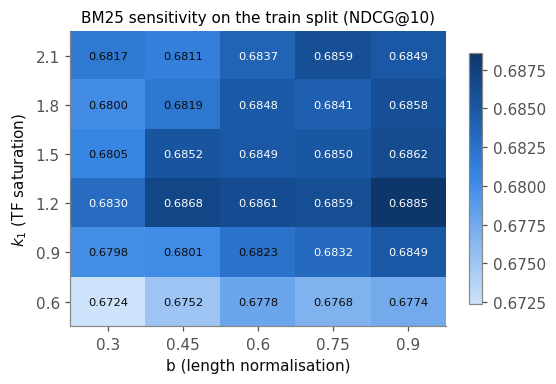

In [15]:
# ============================================================
# 2.2 GRID SEARCH: BM25, TF-IDF ZONES, QL-DIRICHLET, RM3 (TRAIN ONLY)
# ============================================================
TD = 100   # depth of train runs used for tuning
print(f'Tuning on {len(train_qids)} train claims (objective: NDCG@10)\n')

best_bm25, df_bm25 = tune(
    'BM25', [{'k1': k1, 'b': b} for k1 in [0.6, 0.9, 1.2, 1.5, 1.8, 2.1] for b in [0.3, 0.45, 0.6, 0.75, 0.9]],
    lambda k1, b: {q: index.bm25_search(q_tokens[q], k1, b, TD) for q in train_qids},
    train_qids, qrels_train, f'{TUNE_DIR}/bm25.json')

def _tfidf_run(w_title):
    vecs = index.tfidf_vectors(w_title, 1.0, doc_idf=False)          # lnc documents, ltc queries
    return {q: index.tfidf_search(q_tokens[q], vecs, TD) for q in train_qids}
best_tfidf, df_tfidf = tune('TF-IDF lnc.ltc zones', [{'w_title': w} for w in [1.0, 1.5, 2.0, 3.0, 4.0, 6.0]],
                            _tfidf_run, train_qids, qrels_train, f'{TUNE_DIR}/tfidf_zones.json')

best_ql, df_ql = tune('QL-Dirichlet', [{'mu': m} for m in [100, 250, 500, 750, 1000, 1500, 2000, 3000]],
                      lambda mu: {q: ql_dirichlet_search(index, q_tokens[q], mu, TD) for q in train_qids},
                      train_qids, qrels_train, f'{TUNE_DIR}/ql_dirichlet.json')

fp_train = {q: index.bm25_search(q_tokens[q], best_bm25['k1'], best_bm25['b'], 10) for q in train_qids}
def _rm3_run(fb_docs, fb_terms, orig_weight):
    return {q: bm25_weighted_search(index, rm3_query(index, q_tokens[q], fp_train[q], fb_docs, fb_terms, orig_weight),
                                    best_bm25['k1'], best_bm25['b'], TD) for q in train_qids}
best_rm3, df_rm3 = tune('BM25 + RM3', [{'fb_docs': m, 'fb_terms': n, 'orig_weight': l}
                                      for m in [3, 5, 10] for n in [5, 10, 20] for l in [0.3, 0.5, 0.7]],
                        _rm3_run, train_qids, qrels_train, f'{TUNE_DIR}/rm3.json')

tuned_params = {'BM25': best_bm25, 'TF-IDF zones': best_tfidf, 'QL-Dirichlet': best_ql, 'RM3': best_rm3}
save_json(tuned_params, f'{TUNE_DIR}/best_sparse_params.json')

# ---- Figure: BM25 sensitivity heatmap (train) ----
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#898781', 'axes.labelcolor': '#0b0b0b', 'xtick.color': '#52514e',
                     'ytick.color': '#52514e', 'figure.dpi': 110, 'savefig.dpi': 300})
BLUES = LinearSegmentedColormap.from_list('seq_blue', ['#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
piv = df_bm25.pivot(index='k1', columns='b', values='NDCG@10').sort_index(ascending=False)
fig, ax = plt.subplots(figsize=(5.2, 3.6))
im = ax.imshow(piv.values, cmap=BLUES, aspect='auto')
ax.set_xticks(range(len(piv.columns)), [f'{c:g}' for c in piv.columns])
ax.set_yticks(range(len(piv.index)), [f'{r:g}' for r in piv.index])
ax.set_xlabel('b (length normalisation)'); ax.set_ylabel('$k_1$ (TF saturation)')
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        ax.text(j, i, f'{v:.4f}', ha='center', va='center', fontsize=7.5,
                color='#ffffff' if v > piv.values.mean() else '#0b0b0b')
ax.set_title('BM25 sensitivity on the train split (NDCG@10)', fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/fig_bm25_tuning_heatmap.png", bbox_inches='tight')
plt.savefig(f"{DIRS['figures']}/fig_bm25_tuning_heatmap.pdf", bbox_inches='tight')
plt.show()

## 2.3 Dense retrieval: full abstracts and a stronger encoder
* **MiniLM full abstract** vs the mid-term 256-character truncation: an exact ablation of the known bottleneck.
  MiniLM's encoder still truncates at 256 word pieces (about 180 words), but that covers most of an abstract,
  whereas 256 characters is only about 40 words.
* **BGE-base-en-v1.5** (Xiao et al., 2023): a stronger modern bi-encoder with 512-token inputs. Queries get the
  instruction prefix recommended by its authors.

In [16]:
# ============================================================
# 2.3 DENSE ENCODERS: MINILM (FULL ABSTRACT) + BGE-BASE
# ============================================================
full_texts = [corpus[d]['title'] + '. ' + corpus[d]['text'] for d in doc_ids]

emb_minilm_full = encode_cached(sbert, full_texts, f"{DIRS['cache']}/emb_minilm_full.npy")
dense_minilm_full = DenseIndex(emb_minilm_full, doc_ids)

bge = SentenceTransformer('BAAI/bge-base-en-v1.5', device=DEVICE)
if DEVICE == 'cuda':
    bge.half()                                   # fp16 on the T4: ~2x faster, same ranking quality
emb_bge = encode_cached(bge, full_texts, f"{DIRS['cache']}/emb_bge_base.npy", batch_size=32)
dense_bge = DenseIndex(emb_bge.astype('float32'), doc_ids)
BGE_QUERY_PREFIX = 'Represent this sentence for searching relevant passages: '

def encode_queries(model, qids, prefix=''):
    return model.encode([prefix + queries[q] for q in qids], batch_size=128, normalize_embeddings=True,
                        convert_to_numpy=True).astype('float32')

q_emb = {'minilm': {'train': encode_queries(sbert, train_qids), 'test': encode_queries(sbert, test_qids)},
         'bge':    {'train': encode_queries(bge, train_qids, BGE_QUERY_PREFIX),
                    'test':  encode_queries(bge, test_qids, BGE_QUERY_PREFIX)}}
print('✅ Dense indexes ready:', emb_256.shape, emb_minilm_full.shape, emb_bge.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/777 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

✅ Dense indexes ready: (5183, 384) (5183, 384) (5183, 768)


## 2.4 Single-retriever runs (train and test)
Every retriever with its tuned parameters: train runs (top-100, used to tune fusion) and test runs
(top-1,000, for the final evaluation). **BM25 with Anserini defaults (k1 = 0.9, b = 0.4)** is included because it
is the exact configuration the BEIR paper reports. Runs are cached on Drive.

In [17]:
# ============================================================
# 2.4 BUILD ALL SINGLE-RETRIEVER RUNS
# ============================================================
SINGLE = ['TF-IDF lnc.ltc + tuned zones', 'BM25 Anserini default (0.9, 0.4)', 'BM25 tuned', 'QL-Dirichlet tuned',
          'BM25 + RM3 tuned', 'Dense MiniLM 256-char', 'Dense MiniLM full abstract', 'Dense BGE-base']

def build_single_runs(qids, split, depth):
    k1, b = best_bm25['k1'], best_bm25['b']
    vecs = index.tfidf_vectors(best_tfidf['w_title'], 1.0, doc_idf=False)
    R = {n: {} for n in SINGLE}
    for q in tqdm(qids, desc=f'Sparse runs ({split})'):
        R['TF-IDF lnc.ltc + tuned zones'][q]     = index.tfidf_search(q_tokens[q], vecs, depth)
        R['BM25 Anserini default (0.9, 0.4)'][q] = index.bm25_search(q_tokens[q], 0.9, 0.4, depth)
        R['BM25 tuned'][q]                       = bm = index.bm25_search(q_tokens[q], k1, b, depth)
        R['QL-Dirichlet tuned'][q]               = ql_dirichlet_search(index, q_tokens[q], best_ql['mu'], depth)
        qw = rm3_query(index, q_tokens[q], bm[:10], best_rm3['fb_docs'], best_rm3['fb_terms'], best_rm3['orig_weight'])
        R['BM25 + RM3 tuned'][q]                 = bm25_weighted_search(index, qw, k1, b, depth)
    R['Dense MiniLM 256-char']      = dict(zip(qids, dense_256.search(q_emb['minilm'][split], depth)))
    R['Dense MiniLM full abstract'] = dict(zip(qids, dense_minilm_full.search(q_emb['minilm'][split], depth)))
    R['Dense BGE-base']             = dict(zip(qids, dense_bge.search(q_emb['bge'][split], depth)))
    return {'params': tuned_params, 'runs': R}

def load_or_build(split, qids, depth):
    path = f"{DIRS['cache']}/runs_single_{split}.pkl"
    if os.path.exists(path):
        obj = pickle.load(open(path, 'rb'))
        if obj['params'] == tuned_params and set(obj['runs']) == set(SINGLE):
            return obj['runs']
    obj = build_single_runs(qids, split, depth)
    pickle.dump(obj, open(path, 'wb'))
    return obj['runs']

R_train = load_or_build('train', train_qids, 100)
R_test  = load_or_build('test', test_qids, 1000)
print('\nTrain NDCG@10 of each single retriever (used for model selection):')
for n in SINGLE:
    print(f'   {n:<34} {fast_ndcg10(R_train[n], qrels_train, train_qids):.4f}')


Train NDCG@10 of each single retriever (used for model selection):
   TF-IDF lnc.ltc + tuned zones       0.6774
   BM25 Anserini default (0.9, 0.4)   0.6798
   BM25 tuned                         0.6885
   QL-Dirichlet tuned                 0.6730
   BM25 + RM3 tuned                   0.6806
   Dense MiniLM 256-char              0.6074
   Dense MiniLM full abstract         0.6602
   Dense BGE-base                     0.7708


## 2.5 Tuning weighted RRF on the train split
* **Stage A:** every non-empty subset of the six candidate retrievers (63 subsets) × $k \in \{10, 30, 60, 100\}$, equal weights.
* **Stage B:** coordinate ascent on the per-retriever weights $w_i \in \{0, 0.25, 0.5, 1, 1.5, 2, 3\}$, starting from the best subset (2 rounds).

The mid-term counted the lexical signal twice (BM25 and TF-IDF are highly correlated) against one dense vote;
tuning lets the data choose the mix. An **untuned deep RRF** (all six, equal weights, k = 60) is kept as an ablation.

In [18]:
# ============================================================
# 2.5 WEIGHTED RRF — SUBSET SEARCH + COORDINATE ASCENT (TRAIN)
# ============================================================
CANDIDATES = ['TF-IDF lnc.ltc + tuned zones', 'BM25 tuned', 'QL-Dirichlet tuned', 'BM25 + RM3 tuned',
              'Dense MiniLM full abstract', 'Dense BGE-base']
FUSE_DEPTH = 100

def fuse(R, qids, weights, k):
    return {q: rrf([R[n][q] for n in CANDIDATES], k=k, weights=weights, depth=FUSE_DEPTH) for q in qids}

rrf_cache = f'{TUNE_DIR}/rrf.json'
if os.path.exists(rrf_cache):
    rrf_log = load_json(rrf_cache)
else:
    rrf_log = {'stageA': [], 'stageB': []}
    for mask in tqdm(list(itertools.product([0, 1], repeat=len(CANDIDATES)))[1:], desc='RRF stage A (subsets)'):
        for k in [10, 30, 60, 100]:
            rrf_log['stageA'].append({'weights': list(mask), 'k': k,
                                      'NDCG@10': fast_ndcg10(fuse(R_train, train_qids, list(mask), k), qrels_train, train_qids)})
    bestA = max(rrf_log['stageA'], key=lambda r: r['NDCG@10'])
    w, k, best_score = [float(x) for x in bestA['weights']], bestA['k'], bestA['NDCG@10']
    for rnd in range(2):
        for i in range(len(CANDIDATES)):
            for val in [0, 0.25, 0.5, 1, 1.5, 2, 3]:
                trial = w.copy(); trial[i] = val
                if sum(trial) == 0:
                    continue
                s = fast_ndcg10(fuse(R_train, train_qids, trial, k), qrels_train, train_qids)
                rrf_log['stageB'].append({'round': rnd, 'weights': trial, 'k': k, 'NDCG@10': s})
                if s > best_score + 1e-9:
                    w, best_score = trial, s
    rrf_log['best'] = {'weights': w, 'k': k, 'NDCG@10': best_score}
    save_json(rrf_log, rrf_cache)

RRF_W, RRF_K = rrf_log['best']['weights'], rrf_log['best']['k']
print('Best weighted RRF on train:')
for n, wi in zip(CANDIDATES, RRF_W):
    print(f'   {n:<30} w = {wi}')
print(f"   k = {RRF_K} | train NDCG@10 = {rrf_log['best']['NDCG@10']:.4f}")
eq = fast_ndcg10(fuse(R_train, train_qids, [1] * len(CANDIDATES), 60), qrels_train, train_qids)
print(f'   (untuned deep RRF, all six, k=60: train NDCG@10 = {eq:.4f})')

fused_train = fuse(R_train, train_qids, RRF_W, RRF_K)
fused_test  = fuse(R_test,  test_qids,  RRF_W, RRF_K)
fused_test_equal = fuse(R_test, test_qids, [1] * len(CANDIDATES), 60)

Best weighted RRF on train:
   TF-IDF lnc.ltc + tuned zones   w = 0.25
   BM25 tuned                     w = 0.0
   QL-Dirichlet tuned             w = 0.25
   BM25 + RM3 tuned               w = 0.0
   Dense MiniLM full abstract     w = 0.25
   Dense BGE-base                 w = 1.0
   k = 10 | train NDCG@10 = 0.7806
   (untuned deep RRF, all six, k=60: train NDCG@10 = 0.7304)


## 2.6 Cross-encoder re-ranking (tuned on train)
Two re-rankers are compared: **MiniLM-L6 cross-encoder** (`cross-encoder/ms-marco-MiniLM-L-6-v2`, the model family
behind the BEIR paper's "BM25+CE" row) and **BGE-reranker-base**. The re-ranker, the depth $D \in \{20, 50, 100\}$ and the
interpolation weight $\alpha$ are tuned on **300 randomly sampled train claims** (seed 42), to keep GPU time reasonable.
Scores are cached per (query, document) pair.

In [19]:
# ============================================================
# 2.6 CROSS-ENCODER RE-RANKING
# ============================================================
from sentence_transformers import CrossEncoder

RERANKERS = {'MiniLM-L6 CE': 'cross-encoder/ms-marco-MiniLM-L-6-v2', 'BGE-reranker-base': 'BAAI/bge-reranker-base'}
_ce_models = {}

def ce_model(key):
    if key not in _ce_models:
        m = CrossEncoder(RERANKERS[key], device=DEVICE, max_length=512)
        if DEVICE == 'cuda':
            (m.model if hasattr(m, 'model') else m).half()
        _ce_models[key] = m
    return _ce_models[key]

def ce_scores(key, pairs):
    # Score (qid, doc_id) pairs with a cross-encoder; cached on Drive
    path = f"{DIRS['cache']}/ce_scores_{key.replace(' ', '_')}.pkl"
    cache = pickle.load(open(path, 'rb')) if os.path.exists(path) else {}
    todo = sorted({p for p in pairs if p not in cache})
    if todo:
        inputs = [(queries[q], corpus[d]['title'] + ' ' + corpus[d]['text']) for q, d in todo]
        scores = ce_model(key).predict(inputs, batch_size=64, show_progress_bar=True)
        cache.update({p: float(s) for p, s in zip(todo, scores)})
        pickle.dump(cache, open(path, 'wb'))
    return cache

def rerank(base_run, cache, qids, depth, alpha):
    out = {}
    for q in qids:
        cand, rest = base_run[q][:depth], base_run[q][depth:]
        if not cand:
            out[q] = []; continue
        ce = np.array([cache[(q, d)] for d, _ in cand]); rr = np.array([s for _, s in cand])
        mm = lambda x: (x - x.min()) / (x.max() - x.min() + 1e-12)
        s = alpha * mm(ce) + (1 - alpha) * mm(rr)
        order = np.argsort(-s, kind='stable')
        out[q] = [(cand[i][0], 1.0 + float(s[i])) for i in order] + [(d, -float(r)) for r, (d, _) in enumerate(rest, 1)]
    return out

CE_TUNE_QIDS = sorted(random.Random(SEED).sample(train_qids, min(300, len(train_qids))))
ce_cache = {}
for key in RERANKERS:
    ce_cache[key] = ce_scores(key, {(q, d) for q in CE_TUNE_QIDS for d, _ in fused_train[q][:100]})

ce_rows = []
for key in RERANKERS:
    for depth in [20, 50, 100]:
        for alpha in [1.0, 0.8, 0.6, 0.4]:
            ce_rows.append({'reranker': key, 'depth': depth, 'alpha': alpha,
                            'NDCG@10': fast_ndcg10(rerank(fused_train, ce_cache[key], CE_TUNE_QIDS, depth, alpha),
                                                   qrels_train, CE_TUNE_QIDS)})
df_ce = pd.DataFrame(ce_rows).sort_values('NDCG@10', ascending=False)
df_ce.to_csv(f'{TUNE_DIR}/cross_encoder.csv', index=False)
base_tune = fast_ndcg10(fused_train, qrels_train, CE_TUNE_QIDS)
print(f'Train subset ({len(CE_TUNE_QIDS)} claims): tuned RRF without re-ranking NDCG@10 = {base_tune:.4f}')
display(df_ce.head(8).round(4))

best_ce = {key: df_ce[df_ce.reranker == key].iloc[0].to_dict() for key in RERANKERS}
FINAL_CE = df_ce.iloc[0]['reranker']
print(f"Selected re-ranker: {FINAL_CE} (depth {int(best_ce[FINAL_CE]['depth'])}, alpha {best_ce[FINAL_CE]['alpha']})")

# ---- apply to TEST (each re-ranker with its own best train config) ----
test_reranked = {}
for key in RERANKERS:
    D, A = int(best_ce[key]['depth']), float(best_ce[key]['alpha'])
    cache = ce_scores(key, {(q, d) for q in test_qids for d, _ in fused_test[q][:D]})
    test_reranked[key] = rerank(fused_test, cache, test_qids, D, A)

# ---- BEIR "BM25+CE" replication: BM25 (Anserini defaults) top-100 re-ranked by the MiniLM CE ----
bm25_def = R_test['BM25 Anserini default (0.9, 0.4)']
cache = ce_scores('MiniLM-L6 CE', {(q, d) for q in test_qids for d, _ in bm25_def[q][:100]})
bm25_ce_test = rerank(bm25_def, cache, test_qids, 100, 1.0)
save_json({'rrf': {'candidates': CANDIDATES, 'weights': RRF_W, 'k': RRF_K, 'fuse_depth': FUSE_DEPTH},
           'reranker': {k: {kk: (float(vv) if kk != 'reranker' else vv) for kk, vv in v.items()} for k, v in best_ce.items()},
           'final_reranker': FINAL_CE, 'sparse': tuned_params}, f'{TUNE_DIR}/final_pipeline_config.json')
print('✅ Re-ranking done')

Train subset (300 claims): tuned RRF without re-ranking NDCG@10 = 0.7819


,reranker,depth,alpha,NDCG@10
19,BGE-reranker-base,50,0.4,0.7993
23,BGE-reranker-base,100,0.4,0.7988
15,BGE-reranker-base,20,0.4,0.7979
14,BGE-reranker-base,20,0.6,0.7944
18,BGE-reranker-base,50,0.6,0.7916
22,BGE-reranker-base,100,0.6,0.7861
3,MiniLM-L6 CE,20,0.4,0.7825
7,MiniLM-L6 CE,50,0.4,0.7818


Selected re-ranker: BGE-reranker-base (depth 50, alpha 0.4)
✅ Re-ranking done


## 2.7 Final test evaluation, significance tests and comparison with the BEIR paper
* All systems are evaluated **once** on the 300 test claims with all 10 metrics (`trec_eval`-verified code).
* **Significance:** for NDCG@10 and MAP, a paired **Wilcoxon signed-rank test** and a **paired bootstrap** (10,000 resamples,
  95% CI of the mean difference) against (a) the mid-term BM25 and (b) the mid-term hybrid, with
  **Holm–Bonferroni** correction for multiple comparisons.
* **Comparison with an existing paper:** NDCG@10 values reported for SciFact in BEIR (Thakur et al., 2021, Table 2).

In [20]:
# ============================================================
# 2.7 FINAL TEST TABLE + SIGNIFICANCE + BEIR COMPARISON + FIGURES
# ============================================================
FINAL_NAME = f'★ Hybrid RRF tuned + {FINAL_CE} (final)'
systems = {
    'Zone TF-IDF ltc.ltc [mid-term]': runs_p1['TF-IDF ltc.ltc + zones 2:1 [mid-term]'],
    'BM25 rank_bm25 (1.5, 0.75) [mid-term]': runs_p1['BM25 k1=1.5 b=0.75 [mid-term]'],
    'Dense MiniLM 256-char [mid-term]': runs_p1['Dense MiniLM 256-char [mid-term]'],
    'Hybrid RRF top-20 [mid-term]': runs_p1['Hybrid RRF top-20 [mid-term]'],
}
for n in SINGLE:
    if n != 'Dense MiniLM 256-char':
        systems[n] = R_test[n]
systems['Hybrid RRF deep, untuned (6 retrievers, k=60)'] = fused_test_equal
systems['Hybrid RRF tuned'] = fused_test
systems['BM25 + MiniLM CE (BEIR BM25+CE replication)'] = bm25_ce_test
for key in RERANKERS:
    systems[FINAL_NAME if key == FINAL_CE else f'Hybrid RRF tuned + {key}'] = test_reranked[key]

means_p2, perq_p2 = {}, {}
for n, run in systems.items():
    means_p2[n], perq_p2[n] = evaluate(run, qrels_test, test_qids)
table_p2 = results_table(means_p2)
print(f'FINAL RETRIEVAL RESULTS — BEIR SciFact test ({len(test_qids)} claims)')
display(table_p2)
assert all(all(v[2] for v in pytrec_crosscheck(systems[n], qrels_test, means_p2[n]).values()) for n in systems), 'trec_eval mismatch'
print('✅ All numbers verified with trec_eval')

# ---------- significance ----------
def holm(pvals):
    order = np.argsort(pvals); adj = np.empty(len(pvals)); running = 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (len(pvals) - rank) * pvals[i]))
        adj[i] = running
    return adj

def paired_test(sys_name, base_name, metric, n_boot=10000):
    a = np.array([perq_p2[sys_name][q][metric] for q in test_qids])
    b = np.array([perq_p2[base_name][q][metric] for q in test_qids])
    d = a - b
    try:
        p_w = stats.wilcoxon(a, b).pvalue if np.any(d != 0) else 1.0
    except ValueError:
        p_w = 1.0
    boots = d[np.random.default_rng(SEED).integers(0, len(d), (n_boot, len(d)))].mean(axis=1)
    return {'Δ mean': d.mean(), 'CI low': np.percentile(boots, 2.5), 'CI high': np.percentile(boots, 97.5),
            'p (Wilcoxon)': p_w, 'wins': int((d > 0).sum()), 'losses': int((d < 0).sum()), 'ties': int((d == 0).sum())}

sig_rows = []
for base in ['BM25 rank_bm25 (1.5, 0.75) [mid-term]', 'Hybrid RRF top-20 [mid-term]']:
    for metric in ['NDCG@10', 'MAP']:
        block = [{'baseline': base, 'metric': metric, 'system': n, **paired_test(n, base, metric)}
                 for n in systems if '[mid-term]' not in n]
        for r, p in zip(block, holm(np.array([r['p (Wilcoxon)'] for r in block]))):
            r['p (Holm)'] = p; r['significant (α=0.05)'] = '✓' if p < 0.05 and r['CI low'] > 0 else ''
        sig_rows += block
sig = pd.DataFrame(sig_rows)
print('\nPAIRED SIGNIFICANCE TESTS (test set) — vs mid-term baselines')
display(sig[sig.metric == 'NDCG@10'].round(4))

# ---------- comparison with the BEIR paper ----------
beir_paper = {'BM25 (Anserini)': 0.665, 'DeepCT': 0.630, 'SPARTA': 0.582, 'docT5query': 0.675, 'DPR': 0.318,
              'ANCE': 0.507, 'TAS-B': 0.643, 'GenQ': 0.644, 'ColBERT': 0.671, 'BM25+CE': 0.688}
cmp_rows = [{'System': k, 'Source': 'Thakur et al. (2021), BEIR Table 2', 'NDCG@10': v} for k, v in beir_paper.items()]
for n in ['BM25 Anserini default (0.9, 0.4)', 'BM25 + MiniLM CE (BEIR BM25+CE replication)', 'Dense BGE-base',
          'Hybrid RRF tuned', FINAL_NAME]:
    cmp_rows.append({'System': n, 'Source': 'This work', 'NDCG@10': round(means_p2[n]['NDCG@10'], 3)})
beir_cmp = pd.DataFrame(cmp_rows)
print('\nCOMPARISON WITH THE BEIR PAPER (SciFact, NDCG@10)')
display(beir_cmp)

# ---------- save ----------
table_p2.to_csv(f"{DIRS['results']}/p2_retrieval_metrics.csv")
sig.to_csv(f"{DIRS['results']}/p2_significance.csv", index=False)
beir_cmp.to_csv(f"{DIRS['results']}/p2_beir_comparison.csv", index=False)
save_json(perq_p2, f"{DIRS['results']}/p2_per_query.json")
save_json({q: [[d, float(s)] for d, s in systems[FINAL_NAME][q][:100]] for q in test_qids},
          f"{DIRS['runs']}/p2_final_test_run.json")
FINAL_RUN_TEST = {q: systems[FINAL_NAME][q][:100] for q in test_qids}

FINAL RETRIEVAL RESULTS — BEIR SciFact test (300 claims)


,MAP,MAP@10,MRR,MRR@10,NDCG@10,P@5,P@10,R@10,R@100,F1@10
Zone TF-IDF ltc.ltc [mid-term],0.5952,0.5877,0.6079,0.6026,0.6482,0.1640,0.0900,0.8167,0.9376,0.1600
"BM25 rank_bm25 (1.5, 0.75) [mid-term]",0.6443,0.6378,0.6541,0.6494,0.6875,0.1633,0.0910,0.8253,0.9327,0.1619
Dense MiniLM 256-char [mid-term],0.5432,0.5349,0.5536,0.5468,0.5856,0.1380,0.0827,0.7307,0.8887,0.1462
Hybrid RRF top-20 [mid-term],0.6343,0.6300,0.6474,0.6444,0.6915,0.1747,0.0960,0.8644,0.9319,0.1704
TF-IDF lnc.ltc + tuned zones,0.6286,0.6225,0.6383,0.6341,0.6769,0.1640,0.0913,0.8285,0.9332,0.1624
"BM25 Anserini default (0.9, 0.4)",0.6399,0.6326,0.6473,0.6421,0.6782,0.1627,0.0880,0.8044,0.9287,0.1569
BM25 tuned,0.6402,0.6342,0.6477,0.6436,0.6848,0.1633,0.0910,0.8278,0.9293,0.1620
QL-Dirichlet tuned,0.6433,0.6369,0.6525,0.6475,0.6835,0.1607,0.0893,0.8146,0.9202,0.1592
BM25 + RM3 tuned,0.6365,0.6311,0.6455,0.6411,0.6851,0.1653,0.0920,0.8384,0.9320,0.1639
Dense MiniLM full abstract,0.6058,0.5989,0.6127,0.6068,0.6484,0.1647,0.0890,0.7883,0.9250,0.1574


✅ All numbers verified with trec_eval

PAIRED SIGNIFICANCE TESTS (test set) — vs mid-term baselines


,baseline,metric,system,Δ mean,CI low,CI high,p (Wilcoxon),wins,losses,ties,p (Holm),significant (α=0.05)
0,"BM25 rank_bm25 (1.5, 0.75) [mid-term]",NDCG@10,TF-IDF lnc.ltc + tuned zones,-0.0107,-0.0287,0.0074,0.0837,31,46,223,0.4185,
1,"BM25 rank_bm25 (1.5, 0.75) [mid-term]",NDCG@10,"BM25 Anserini default (0.9, 0.4)",-0.0093,-0.0211,0.0028,0.0480,17,35,248,0.3360,
2,"BM25 rank_bm25 (1.5, 0.75) [mid-term]",NDCG@10,BM25 tuned,-0.0027,-0.0109,0.0049,0.3457,17,19,264,1.0000,
3,"BM25 rank_bm25 (1.5, 0.75) [mid-term]",NDCG@10,QL-Dirichlet tuned,-0.0040,-0.0197,0.0117,0.4914,26,45,229,1.0000,
4,"BM25 rank_bm25 (1.5, 0.75) [mid-term]",NDCG@10,BM25 + RM3 tuned,-0.0024,-0.0167,0.0120,0.6897,35,40,225,1.0000,
5,"BM25 rank_bm25 (1.5, 0.75) [mid-term]",NDCG@10,Dense MiniLM full abstract,-0.0391,-0.0739,-0.0048,0.0490,62,76,162,0.3360,
6,"BM25 rank_bm25 (1.5, 0.75) [mid-term]",NDCG@10,Dense BGE-base,0.0546,0.0216,0.0869,0.0004,87,43,170,0.0036,✓
7,"BM25 rank_bm25 (1.5, 0.75) [mid-term]",NDCG@10,"Hybrid RRF deep, untuned (6 retrievers, k=60)",0.0490,0.0317,0.0668,0.0000,75,14,211,0.0000,✓
8,"BM25 rank_bm25 (1.5, 0.75) [mid-term]",NDCG@10,Hybrid RRF tuned,0.0752,0.0473,0.1027,0.0000,95,32,173,0.0000,✓
9,"BM25 rank_bm25 (1.5, 0.75) [mid-term]",NDCG@10,BM25 + MiniLM CE (BEIR BM25+CE replication),0.0015,-0.0275,0.0304,0.7712,58,51,191,1.0000,



COMPARISON WITH THE BEIR PAPER (SciFact, NDCG@10)


,System,Source,NDCG@10
0,BM25 (Anserini),"Thakur et al. (2021), BEIR Table 2",0.665
1,DeepCT,"Thakur et al. (2021), BEIR Table 2",0.630
2,SPARTA,"Thakur et al. (2021), BEIR Table 2",0.582
3,docT5query,"Thakur et al. (2021), BEIR Table 2",0.675
4,DPR,"Thakur et al. (2021), BEIR Table 2",0.318
5,ANCE,"Thakur et al. (2021), BEIR Table 2",0.507
6,TAS-B,"Thakur et al. (2021), BEIR Table 2",0.643
7,GenQ,"Thakur et al. (2021), BEIR Table 2",0.644
8,ColBERT,"Thakur et al. (2021), BEIR Table 2",0.671
9,BM25+CE,"Thakur et al. (2021), BEIR Table 2",0.688


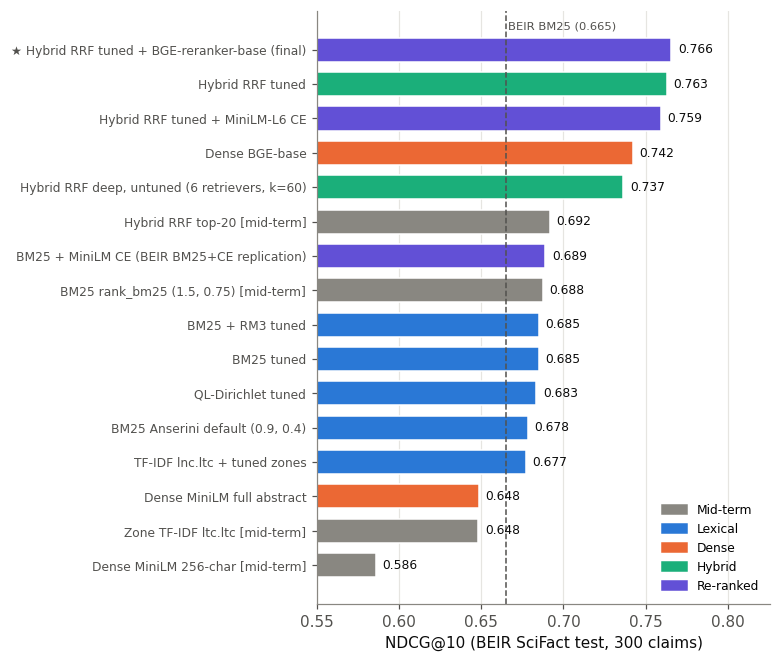

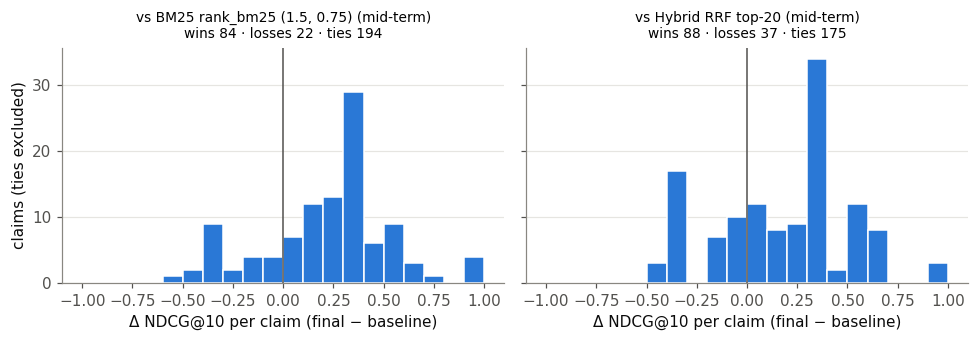

✅ Part 2 complete — tables in results/, figures in figures/, final run saved for Part 3


In [21]:
# ============================================================
# 2.7b FIGURES FOR THE REPORT
# ============================================================
FAMILY_COLORS = {'Mid-term': '#898781', 'Lexical': '#2a78d6', 'Dense': '#eb6834', 'Hybrid': '#1baf7a', 'Re-ranked': '#6250d6'}
def family(n):
    if '[mid-term]' in n: return 'Mid-term'
    if 'CE' in n or 'reranker' in n.lower() or '★' in n: return 'Re-ranked'
    if 'Hybrid' in n: return 'Hybrid'
    if 'Dense' in n: return 'Dense'
    return 'Lexical'

# Figure: NDCG@10 of every system
order = table_p2['NDCG@10'].sort_values().index
fig, ax = plt.subplots(figsize=(7.2, 0.32 * len(order) + 1.0))
cols = [FAMILY_COLORS[family(n)] for n in order]
ax.barh(range(len(order)), table_p2.loc[order, 'NDCG@10'], color=cols, height=0.7, edgecolor='white', linewidth=1)
for i, n in enumerate(order):
    ax.text(table_p2.loc[n, 'NDCG@10'] + 0.004, i, f"{table_p2.loc[n, 'NDCG@10']:.3f}", va='center', fontsize=8, color='#0b0b0b')
ax.set_yticks(range(len(order)), order, fontsize=8)
ax.axvline(0.665, color='#52514e', ls='--', lw=1); ax.text(0.666, len(order) - 0.4, 'BEIR BM25 (0.665)', fontsize=7.5, color='#52514e')
lo = max(0.0, np.floor((table_p2['NDCG@10'].min() - 0.03) * 20) / 20)
ax.set_xlim(lo, table_p2['NDCG@10'].max() + 0.06); ax.set_xlabel(f'NDCG@10 (BEIR SciFact test, {len(test_qids)} claims)')
ax.grid(axis='x', color='#e6e5e1', lw=0.8); ax.set_axisbelow(True)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=f) for f, c in FAMILY_COLORS.items()], loc='lower right', fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/fig_retrieval_ndcg.png", bbox_inches='tight'); plt.savefig(f"{DIRS['figures']}/fig_retrieval_ndcg.pdf", bbox_inches='tight')
plt.show()

# Figure: per-query NDCG@10 difference, final system vs the two mid-term baselines
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, base in zip(axes, ['BM25 rank_bm25 (1.5, 0.75) [mid-term]', 'Hybrid RRF top-20 [mid-term]']):
    d = np.array([perq_p2[FINAL_NAME][q]['NDCG@10'] - perq_p2[base][q]['NDCG@10'] for q in test_qids])
    ax.hist(d[d != 0], bins=np.linspace(-1, 1, 21), color='#2a78d6', edgecolor='white', linewidth=1)
    ax.axvline(0, color='#52514e', lw=1)
    ax.set_title(f'vs {base.replace(" [mid-term]", "")} (mid-term)\nwins {(d>0).sum()} · losses {(d<0).sum()} · ties {(d==0).sum()}', fontsize=9)
    ax.set_xlabel('Δ NDCG@10 per claim (final − baseline)')
    ax.grid(axis='y', color='#e6e5e1', lw=0.8); ax.set_axisbelow(True)
axes[0].set_ylabel('claims (ties excluded)')
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/fig_per_query_delta.png", bbox_inches='tight'); plt.savefig(f"{DIRS['figures']}/fig_per_query_delta.pdf", bbox_inches='tight')
plt.show()
print('✅ Part 2 complete — tables in results/, figures in figures/, final run saved for Part 3')

# Part 3 — Generative claim verification with cited evidence
The mid-term built an *extractive* answer by copying sentences. Here a local LLM (**Qwen2.5-3B-Instruct**,
fp16 on the T4, greedy decoding so results are reproducible) reads the **top-5 abstracts**, each tagged with its
`[doc_id]`, and writes a verdict and a cited explanation:
```
VERDICT: SUPPORTED | REFUTED | NOT ENOUGH INFO
EXPLANATION: 2–4 sentences, each ending with [doc_id] citations
```
The prompt forbids outside knowledge and asks for NOT ENOUGH INFO when the abstracts do not decide the claim.
This matters because 112 of the 300 test claims are NEI: the cited abstract is on-topic but has no evidence.

**Experiment — does better retrieval give better answers?** The same LLM is run with three evidence sources:

| Context | Evidence given to the LLM |
|---|---|
| `final` | top-5 of our final retriever (Part 2) |
| `midterm` | top-5 of the mid-term hybrid RRF |
| `oracle` | the gold cited abstracts: an upper bound on what retrieval can provide |

We also generate for **200 train claims** (final retriever), so that Part 4 can tune RTS thresholds
without touching the test set, and we rebuild the **mid-term extractive answers** as a baseline.
All generations are saved incrementally to Drive, so an interrupted run resumes where it stopped.

## 3.1 Load the LLM

In [ ]:
# ============================================================
# 3.1 LOAD QWEN2.5-3B-INSTRUCT (fp16) — free GPU memory first
# ============================================================
import gc
from transformers import AutoTokenizer, AutoModelForCausalLM

for _name in ['bge']:
    if _name in globals():
        del globals()[_name]
_ce_models.clear(); gc.collect(); torch.cuda.empty_cache()

LLM_NAME = 'Qwen/Qwen2.5-3B-Instruct'
tok = AutoTokenizer.from_pretrained(LLM_NAME, padding_side='left')
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, torch_dtype=torch.float16 if DEVICE == 'cuda' else torch.float32,
                                           device_map=DEVICE)
llm.eval()
GEN_CFG = {'max_new_tokens': 220, 'do_sample': False, 'temperature': None, 'top_p': None, 'top_k': None}
if DEVICE == 'cuda':
    print(f'✅ {LLM_NAME} loaded | GPU memory used: {torch.cuda.memory_allocated() / 1e9:.1f} GB')

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

## 3.2 Prompt, generation and parsing
* **Prompt:** system role = careful biomedical fact-checker that uses *only* the given abstracts.
* **Batched greedy generation** (prompts sorted by length; the batch size halves automatically on GPU out-of-memory).
* **Parsing:** the verdict is mapped to the SciFact label set {SUPPORT, CONTRADICT, NEI}. The explanation is split into
  sentences, citations are extracted, and citations to abstracts that were *not* in the context are flagged as
  **invalid citations** (a form of hallucination). Outputs that break the format are counted, not hidden.

In [ ]:
# ============================================================
# 3.2 PROMPT + BATCHED GENERATION + ROBUST PARSING
# ============================================================
SYSTEM_PROMPT = ('You are a careful biomedical fact-checking assistant. You verify scientific claims using ONLY '
                 'the abstracts provided by the user. Never use outside knowledge. Be concise and precise.')
MAX_ABSTRACT_CHARS = 2500   # ~550 tokens per abstract; >98% of SciFact abstracts are shorter

def build_prompt(claim, doc_list):
    blocks = []
    for d in doc_list:
        text = corpus[d]['text']
        text = text if len(text) <= MAX_ABSTRACT_CHARS else text[:MAX_ABSTRACT_CHARS] + ' ...'
        blocks.append(f'[{d}] {corpus[d]["title"]}\n{text}')
    user = (f'Claim: {claim}\n\nAbstracts:\n\n' + '\n\n'.join(blocks) + '\n\n'
            'Instructions:\n'
            '1. Decide whether the abstracts SUPPORT the claim, REFUTE it, or do not contain enough information. '
            'Answer NOT ENOUGH INFO if no abstract directly addresses the claim.\n'
            '2. Write 2-4 short sentences explaining your verdict. Every sentence must end with the id(s) of the '
            'abstract(s) it relies on in square brackets, for example [12345].\n'
            '3. Use exactly this format:\n'
            'VERDICT: <SUPPORTED or REFUTED or NOT ENOUGH INFO>\n'
            'EXPLANATION: <your sentences>')
    msgs = [{'role': 'system', 'content': SYSTEM_PROMPT}, {'role': 'user', 'content': user}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

_VERDICT_RE = re.compile(r'VERDICT\s*[:\-]\s*\**\s*([A-Za-z ]+)', re.I)
_CITE_RE = re.compile(r'\[([^\[\]]+)\]')

def map_verdict(s):
    s = s.upper()
    if 'NOT ENOUGH' in s or 'INSUFFICIENT' in s or s.strip().startswith('NEI'):
        return 'NEI'
    if 'REFUT' in s or 'CONTRADICT' in s:
        return 'CONTRADICT'
    if 'SUPPORT' in s:
        return 'SUPPORT'
    return None

def split_sentences(text):
    parts = re.split(r'(?<=[.!?])\s+', text.strip())
    out = []
    for p in parts:
        p = p.strip()
        # citations written after the full stop ("... effect. [123] Next sentence") belong to the previous sentence
        m = re.match(r'^((?:\[[^\[\]]+\]\s*[.,;]?\s*)+)(.*)$', p)
        if m and out:
            out[-1] += ' ' + m.group(1).strip()
            p = m.group(2).strip()
        if p:
            out.append(p)
    return out

def parse_output(raw, context_docs):
    m = _VERDICT_RE.search(raw)
    verdict = map_verdict(m.group(1)) if m else map_verdict(raw.split('\n')[0])
    parse_ok = m is not None and verdict is not None
    expl = re.split(r'EXPLANATION\s*[:\-]\s*', raw, flags=re.I)
    expl = expl[1] if len(expl) > 1 else (raw[m.end():] if m else raw)
    valid = set(context_docs)
    sentences = []
    for s in split_sentences(expl):
        ids = [x.strip() for c in _CITE_RE.findall(s) for x in re.split(r'[,;\s]+', c) if x.strip()]
        ids = [re.sub(r'\D', '', x) for x in ids if re.sub(r'\D', '', x)]
        clean = re.sub(r'\s+', ' ', _CITE_RE.sub('', s.replace('**', ''))).strip()
        clean = re.sub(r'\s+([.,;:])', r'\1', clean)
        if len(clean) < 8:
            continue
        sentences.append({'text': clean, 'cited': [i for i in ids if i in valid],
                          'invalid_cited': [i for i in ids if i not in valid]})
    return {'verdict': verdict or 'NEI', 'parse_ok': parse_ok, 'sentences': sentences}

@torch.no_grad()
def generate_batch(prompts):
    enc = tok(prompts, return_tensors='pt', padding=True).to(llm.device)
    out = llm.generate(**enc, **GEN_CFG, pad_token_id=tok.pad_token_id)
    return tok.batch_decode(out[:, enc['input_ids'].shape[1]:], skip_special_tokens=True)

def run_generation(name, items, batch_size=8):
    # items: {qid: (claim, [doc_ids])}. Resumable: results are saved to Drive after every batch.
    path = f"{DIRS['results']}/p3_generations_{name}.json"
    done = load_json(path) if os.path.exists(path) else {}
    todo = sorted([q for q in items if q not in done], key=lambda q: -len(build_prompt(*items[q])))
    pbar = tqdm(total=len(todo), desc=f'Generating [{name}]')
    i = 0
    while i < len(todo):
        batch = todo[i:i + batch_size]
        try:
            t0 = time.time()
            outs = generate_batch([build_prompt(*items[q]) for q in batch])
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            batch_size = max(1, batch_size // 2)
            print(f'   OOM → batch size {batch_size}')
            continue
        dt = (time.time() - t0) / len(batch)
        for q, raw in zip(batch, outs):
            claim, docs = items[q]
            done[q] = {'qid': q, 'claim': claim, 'context': name, 'doc_ids': docs, 'raw': raw.strip(),
                       'seconds': round(dt, 2), **parse_output(raw, docs)}
        save_json(done, path)
        i += len(batch); pbar.update(len(batch))
    pbar.close()
    return done

# quick smoke test on one claim
_q = test_qids[0]
_docs = [d for d, _ in FINAL_RUN_TEST[_q][:5]]
_raw = generate_batch([build_prompt(queries[_q], _docs)])[0]
print('CLAIM :', queries[_q]); print('GOLD  :', claims_gold[_q]['label']); print('OUTPUT:\n' + _raw)
print('PARSED:', parse_output(_raw, _docs))

## 3.3 Run the generations (≈ 45–60 min on a T4 the first time; fully cached afterwards)
Order: `final` (the main system), `train` (for Part 4 tuning), `midterm`, `oracle`.

In [ ]:
# ============================================================
# 3.3 GENERATE FOR ALL EVIDENCE CONTEXTS
# ============================================================
TOPK_CTX = 5
# final retriever run for 200 train claims (same pipeline as test: tuned RRF + selected re-ranker)
_D, _A = int(best_ce[FINAL_CE]['depth']), float(best_ce[FINAL_CE]['alpha'])
GEN_TRAIN_QIDS = sorted(random.Random(SEED).sample(CE_TUNE_QIDS, min(200, len(CE_TUNE_QIDS))))
final_run_train = rerank(fused_train, ce_cache[FINAL_CE], GEN_TRAIN_QIDS, _D, _A)

contexts = {
    'final':   {q: (queries[q], [d for d, _ in FINAL_RUN_TEST[q][:TOPK_CTX]]) for q in test_qids},
    'train':   {q: (queries[q], [d for d, _ in final_run_train[q][:TOPK_CTX]]) for q in GEN_TRAIN_QIDS},
    'midterm': {q: (queries[q], [d for d, _ in runs_p1['Hybrid RRF top-20 [mid-term]'][q][:TOPK_CTX]]) for q in test_qids},
    'oracle':  {q: (queries[q], list(qrels_test[q].keys())[:TOPK_CTX]) for q in test_qids},
}
gens = {}
for name, items in contexts.items():
    gens[name] = run_generation(name, items)
print('✅ All generations done')

## 3.4 Mid-term extractive baseline (rebuilt on the final retrieval)
The same algorithm as the mid-term: split the top-5 abstracts into sentences (> 40 characters), score them by SBERT
cosine to the claim, and keep the top 4 with at most one per abstract. It has no verdict; it serves as the
extractive baseline for RTS in Parts 4–5.

In [ ]:
# ============================================================
# 3.4 EXTRACTIVE RAG BASELINE (MID-TERM ALGORITHM)
# ============================================================
def extractive_answer(claim, doc_list, n_sent=4):
    cands = []
    for d in doc_list:
        for s in re.split(r'(?<=[.!?])\s+', corpus[d]['title'] + '. ' + corpus[d]['text']):
            if len(s.strip()) > 40:
                cands.append((d, s.strip()))
    if not cands:
        return []
    e = sbert.encode([claim] + [s for _, s in cands], normalize_embeddings=True, convert_to_numpy=True)
    sims = e[1:] @ e[0]
    chosen, used = [], set()
    for i in np.argsort(-sims):
        d, s = cands[i]
        if d not in used:
            chosen.append({'text': s, 'cited': [d], 'invalid_cited': []}); used.add(d)
        if len(chosen) == n_sent:
            break
    return chosen

ext_path = f"{DIRS['results']}/p3_generations_extractive.json"
if os.path.exists(ext_path):
    gens['extractive'] = load_json(ext_path)
else:
    gens['extractive'] = {q: {'qid': q, 'claim': queries[q], 'context': 'extractive',
                              'doc_ids': contexts['final'][q][1], 'raw': '', 'verdict': None, 'parse_ok': True,
                              'sentences': extractive_answer(queries[q], contexts['final'][q][1])} for q in test_qids}
    save_json(gens['extractive'], ext_path)
print(f"✅ Extractive answers for {len(gens['extractive'])} test claims")

## 3.5 Quick look at the generations
A preview only; the full Precision / Recall / F1 evaluation is in Part 5.
* **Parse rate:** share of outputs in the required format.
* **Verdict accuracy and macro-F1** against the gold SciFact labels (SUPPORT / CONTRADICT / NEI).
* **Citation behaviour:** sentences per answer, share of sentences with at least one valid citation, and share of
  sentences citing an abstract that was not in the context (*invalid citation*).
* **Evidence recall@5:** share of claims whose context contains at least one gold cited abstract.

In [ ]:
# ============================================================
# 3.5 GENERATION SUMMARY
# ============================================================
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
LABELS = ['SUPPORT', 'CONTRADICT', 'NEI']

rows = []
for name in ['final', 'midterm', 'oracle', 'train']:
    G = gens[name]
    qs = list(G)
    qrels_ = qrels_test if name != 'train' else qrels_train
    y_true = [claims_gold[q]['label'] for q in qs]
    y_pred = [G[q]['verdict'] for q in qs]
    sents = [s for q in qs for s in G[q]['sentences']]
    rows.append({'context': name, 'claims': len(qs),
                 'parse rate': np.mean([G[q]['parse_ok'] for q in qs]),
                 'evidence recall@5': np.mean([any(d in qrels_.get(q, {}) for d in G[q]['doc_ids']) for q in qs]),
                 'verdict accuracy': accuracy_score(y_true, y_pred),
                 'macro-F1': f1_score(y_true, y_pred, labels=LABELS, average='macro', zero_division=0),
                 'sentences / answer': len(sents) / len(qs),
                 'sentences with valid citation': np.mean([len(s['cited']) > 0 for s in sents]) if sents else 0,
                 'sentences with invalid citation': np.mean([len(s['invalid_cited']) > 0 for s in sents]) if sents else 0,
                 'sec / claim': np.mean([G[q]['seconds'] for q in qs])})
gen_summary = pd.DataFrame(rows).set_index('context').round(4)
display(gen_summary)
gen_summary.to_csv(f"{DIRS['results']}/p3_generation_summary.csv")

print('\nConfusion matrix — final context (rows = gold, cols = predicted):')
G = gens['final']
cm = confusion_matrix([claims_gold[q]['label'] for q in G], [G[q]['verdict'] for q in G], labels=LABELS)
display(pd.DataFrame(cm, index=[f'gold {l}' for l in LABELS], columns=[f'pred {l}' for l in LABELS]))

print('\nExamples (final context):')
for lab in LABELS:
    q = next((q for q in test_qids if claims_gold[q]['label'] == lab), None)
    if q is None:
        continue
    g = G[q]
    print(f"\n── CLAIM [{q}] gold={lab} predicted={g['verdict']}\n   {g['claim']}")
    for s in g['sentences']:
        print(f"   • {s['text']}  cites={s['cited']}{'  INVALID=' + str(s['invalid_cited']) if s['invalid_cited'] else ''}")

In [ ]:
# ============================================================
# 3.6 DRIVE USAGE
# ============================================================
def folder_size_mb(p):
    return sum(os.path.getsize(os.path.join(r, f)) for r, _, fs in os.walk(p) for f in fs) / 1e6
for k, p in DIRS.items():
    print(f'   {k:<8} {folder_size_mb(p):8.1f} MB')
print(f'   {"TOTAL":<8} {sum(folder_size_mb(p) for p in DIRS.values()):8.1f} MB')
print('✅ Part 3 complete')

# Part 4 — Retrieval Transparency Score v2 (RTS v2)
**Why v1 is not enough.** RTS v1 scored a sentence by its maximum cosine similarity to the first 400 characters of the
retrieved documents. (i) Cosine similarity cannot see negation: *"X increases Y"* and *"X decreases Y"* are near-identical
embeddings. (ii) Comparing extractive sentences with the documents they were copied from is close to circular.
(iii) Truncation hides evidence. Part 3 also showed a concrete failure: the LLM **never** outputs REFUTED, and once wrote
*"This supports the claim"* for a contradicted claim.

### RTS v2 for one answer sentence $s$
1. **Sentence type.** Meta / abstention sentences (*"None of the abstracts address…"*) are separated from factual sentences;
   only factual sentences are scored.
2. **Span attribution.** Every abstract is split into spans $\mathcal{S}(d)$: the title, each sentence, and every 2-sentence
   window. For the context documents $D$ we take the top-$m$ spans by SBERT cosine: $\;T=\text{top-}m_{\,u\in\cup_{d\in D}\mathcal{S}(d)}\cos(s,u)$.
3. **Semantic similarity:** $\text{sim}(s,u)=\cos(E(s),E(u))$.
4. **NLI grounding check** with a cross-encoder (premise $u$, hypothesis $s$): $P_e(u,s),\,P_n(u,s),\,P_c(u,s)$.
5. **Composite score with contradiction penalty:**
$$\text{support}(s)=\max_{u\in T}\big[\alpha\,\text{sim}(s,u)+(1-\alpha)\,P_e(u,s)\big],\qquad
\text{contra}(s)=\max_{u\in T}P_c(u,s)$$
$$\boxed{\text{RTS}_{v2}(s)=\text{support}(s)\cdot\big(1-\lambda\,\text{contra}(s)\big)}$$
6. **Decision and label:** a sentence is predicted *hallucinated* if $\text{RTS}_{v2}<\tau$; how the contradiction signal is added
   (never / always / only when no span entails the sentence) is selected on train. For display,
   CONTRADICTED if $\text{contra}\ge\tau_c$ (CONFLICTING if another span also entails it), otherwise HIGH ($\ge\tau_h$, ≥95% grounded on train),
   MED (uncertain) or LOW ($<\tau_l$, ≥90% hallucinated on train).
7. **Provenance and citation check:** the best span $u^*$ and its document are reported; a citation is *faithful* if $u^*$
   comes from an abstract the sentence cites.
8. **Answer level:** $\text{RTS}_{mean}$ and $\text{RTS}_{min}$ (weakest-link) over factual sentences.

All parameters ($\alpha,\lambda,\tau,\tau_h,\tau_c$, the NLI model, and the verdict-correction thresholds) are tuned on
**train claims only**.

## 4.1 Span index over the whole corpus

In [ ]:
# ============================================================
# 4.1 SPAN INDEX: TITLE + SENTENCES + 2-SENTENCE WINDOWS (SBERT, CACHED)
# ============================================================
def doc_sentences(d):
    sents = abstract_sentences.get(d) or re.split(r'(?<=[.!?])\s+', corpus[d]['text'])
    return [s.strip() for s in sents if s and s.strip()]

span_ids, span_texts, span_doc, doc_span_range = [], [], [], {}
for d in doc_ids:
    start = len(span_ids)
    sents = doc_sentences(d)
    items = [(f'{d}:T', corpus[d]['title'])] + [(f'{d}:{i}', s) for i, s in enumerate(sents)] + \
            [(f'{d}:{i}-{i+1}', sents[i] + ' ' + sents[i + 1]) for i in range(len(sents) - 1)]
    for sid, txt in items:
        span_ids.append(sid); span_texts.append(txt); span_doc.append(d)
    doc_span_range[d] = (start, len(span_ids))
span_emb = encode_cached(sbert, span_texts, f"{DIRS['cache']}/emb_minilm_spans.npy", batch_size=128)
print(f'✅ {len(span_ids):,} spans from {len(doc_ids):,} abstracts | embeddings {span_emb.shape}')

# RTS v1 document embeddings (exactly as in the mid-term: title + ". " + text[:400])
emb_v1 = encode_cached(sbert, [corpus[d]['title'] + '. ' + corpus[d]['text'][:400] for d in doc_ids],
                       f"{DIRS['cache']}/emb_minilm_rts_v1.npy")
doc_row = {d: i for i, d in enumerate(doc_ids)}

## 4.2 NLI models (cross-encoders) with a persistent cache
Two candidates, selected on train data in 4.4:
* `cross-encoder/nli-deberta-v3-base` (SNLI + MultiNLI)
* `MoritzLaurer/DeBERTa-v3-large-mnli-fever-anli-ling-wanli` (also trained on FEVER, a fact-verification dataset)

Label order differs between models, so it is read from each model's config. Scores are cached per (model, premise, hypothesis).

In [ ]:
# ============================================================
# 4.2 NLI CROSS-ENCODERS
# ============================================================
from transformers import AutoModelForSequenceClassification
NLI_MODELS = {'DeBERTa-v3-base NLI': 'cross-encoder/nli-deberta-v3-base',
              'DeBERTa-v3-large NLI (+FEVER/ANLI)': 'MoritzLaurer/DeBERTa-v3-large-mnli-fever-anli-ling-wanli'}

class NLIScorer:
    def __init__(self, key):
        self.key, name = key, NLI_MODELS[key]
        self.tok = AutoTokenizer.from_pretrained(name)
        self.model = AutoModelForSequenceClassification.from_pretrained(name).to(DEVICE).eval()   # fp32: DeBERTa-v3 is unstable in fp16
        lab = {v.lower(): int(k) for k, v in self.model.config.id2label.items()}
        find = lambda key: next(i for l, i in lab.items() if l.startswith(key))
        self.order = [find('entail'), find('neutral'), find('contradict')]
        self.path = f"{DIRS['cache']}/nli_{key.split()[0]}.pkl"
        self.cache = pickle.load(open(self.path, 'rb')) if os.path.exists(self.path) else {}

    @torch.no_grad()
    def __call__(self, pairs, batch_size=32):
        # pairs: list of (premise, hypothesis) → array (n, 3) = [P_entail, P_neutral, P_contradict]
        todo = sorted({p for p in pairs if p not in self.cache}, key=lambda p: len(p[0]) + len(p[1]))
        for i in tqdm(range(0, len(todo), batch_size), desc=f'NLI [{self.key}]', disable=len(todo) < 500):
            chunk = todo[i:i + batch_size]
            enc = self.tok([p for p, _ in chunk], [h for _, h in chunk], truncation=True, max_length=320,
                           padding=True, return_tensors='pt').to(DEVICE)
            probs = torch.softmax(self.model(**enc).logits.float(), dim=-1)[:, self.order].cpu().numpy()
            self.cache.update({p: pr for p, pr in zip(chunk, probs)})
        if todo:
            pickle.dump(self.cache, open(self.path, 'wb'))
        return np.array([self.cache[p] for p in pairs]) if pairs else np.zeros((0, 3))

    def release(self):
        del self.model; gc.collect(); torch.cuda.empty_cache()
print('✅ NLI scorer defined')

## 4.3 Feature extraction and the RTS v2 formula
For any hypothesis sentence and set of context documents we store the top-$m$ span similarities and their NLI
probabilities. RTS v2 for any $(\alpha,\lambda)$ is then a cheap vectorised computation, which makes tuning fast.
Hypotheses are lightly cleaned before scoring: leftover citation commas and leading attributions such as
*"Abstract X reports that…"* are removed. The original sentence is kept for display.

In [ ]:
# ============================================================
# 4.3 FEATURES (TOP-m SPANS: COSINE + NLI) AND RTS FORMULAS
# ============================================================
TOP_M = 5
META_RE = re.compile(r"(none of the (provided |given )?(abstracts?|studies)|\bno (provided |given )?(abstract|study)\b|"
                     r"(abstracts?|studies) (do|does|did) not|not enough (information|evidence)|insufficient (information|evidence)|"
                     r"(do|does|did) not (directly|specifically|explicitly) (address|mention|discuss|examine|investigate|state))",
                     re.I)
DISC_RE = re.compile(r"^(?:additionally|furthermore|moreover|in addition|also|similarly|however|finally),?\s+", re.I)
LEADVERB_RE = re.compile(r"^(?:also\s+)?(?:demonstrates?|shows?|reports?|finds?|found|indicates?|suggests?|provides? evidence|"
                         r"supports? the claim|states?|notes?|highlights?|confirms?|mentions?)\s+(?:by indicating\s+)?(?:that\s+)?", re.I)
ATTRIB_RE = re.compile(r"^(?:(?:the )?(?:first|second|third|fourth|fifth|another|this|one|other)?\s*(?:abstracts?|stud(?:y|ies)|"
                       r"papers?|authors?|trials?|results?|findings?|evidence)\s*(?:\w+\s+){0,3}?"
                       r"(?:that|shows?|showed|reports?|reported|finds?|found|demonstrates?|demonstrated|suggests?|"
                       r"suggested|indicates?|indicated|provides? evidence that|states?)\s+(?:that\s+)?)", re.I)

CONCL_RE = re.compile(r"^(?:this|which|these (?:findings|results|data)|together,? these)\s+(?:\w+\s+){0,2}?"
                      r"(?:supports?|suggests?|indicates?|confirms?|implies|shows?|means?)\s+(?:the claim\s+)?(?:that\s+)?", re.I)

def is_meta(text):
    return bool(META_RE.search(text))

def clean_hypothesis(t):
    t = re.sub(r'\s*,(\s*,)+', ',', t)
    t = re.sub(r'\b(Abstracts?|Studies)\s*,\s*(and\s+)?', r'\1 ', t)
    t = re.sub(r'\s{2,}', ' ', t).strip()
    t2 = DISC_RE.sub('', t)
    t2 = CONCL_RE.sub('', ATTRIB_RE.sub('', t2)).strip()
    if t2[:1].islower():                         # sentence started with a citation: "[123] demonstrates that ..."
        t2 = LEADVERB_RE.sub('', t2).strip()
    return (t2[0].upper() + t2[1:]) if len(t2) > 15 else t

def context_span_idx(docs):
    idx = [i for d in docs if d in doc_span_range for i in range(*doc_span_range[d])]
    return np.array(idx, dtype=int)

def extract_features(items, nli, m=TOP_M):
    # items: list of (hypothesis_text, context_docs). Returns dict of arrays (n, m) + best span ids.
    hyps = [clean_hypothesis(h) for h, _ in items]
    H = sbert.encode(hyps, batch_size=128, normalize_embeddings=True, convert_to_numpy=True)
    S = np.zeros((len(items), m)); top_span = np.full((len(items), m), -1)
    pairs = []
    for n, ((_, docs), h) in enumerate(zip(items, hyps)):
        idx = context_span_idx(docs)
        if len(idx) == 0:
            continue
        sims = span_emb[idx] @ H[n]
        k = min(m, len(idx)); best = np.argsort(-sims)[:k]
        S[n, :k] = sims[best]; top_span[n, :k] = idx[best]
        pairs += [(span_texts[idx[j]], h) for j in best]
    probs = nli(pairs)
    PE, PC = np.zeros_like(S), np.zeros_like(S)
    c = 0
    for n in range(len(items)):
        for j in range(m):
            if top_span[n, j] >= 0:
                PE[n, j], PC[n, j] = probs[c, 0], probs[c, 2]; c += 1
    V1 = np.array([max((float(emb_v1[doc_row[d]] @ H[n]) for d in docs if d in doc_row), default=0.0)
                   for n, (_, docs) in enumerate(items)])
    return {'S': S, 'PE': PE, 'PC': PC, 'top_span': top_span, 'V1': V1, 'hyp': hyps}

def rts_v2(F, alpha, lam):
    comb = alpha * F['S'] + (1 - alpha) * F['PE']
    support, contra = comb.max(axis=1), F['PC'].max(axis=1)
    return support * (1 - lam * contra), support, contra, comb.argmax(axis=1)

def detector_scores(F, alpha, lam):
    # all detectors: higher = more grounded
    return {'RTS v1 (doc cosine, mid-term)': F['V1'],
            'SBERT span similarity': F['S'].max(axis=1),
            'NLI only (max P_entail)': F['PE'].max(axis=1),
            'RTS v2': rts_v2(F, alpha, lam)[0]}
print('✅ Feature extraction ready')

## 4.4 Tuning benchmark from TRAIN claims (+ the same generator for test, used in Part 5)
Each item is a sentence to verify against a context of 5 abstracts (the claim's gold cited abstracts plus top retrieved
ones). Labels come from humans (SciFact) or are true by construction:

| Category | Source | Label |
|---|---|---|
| `claim SUPPORT` | SciFact claim whose evidence supports it | grounded |
| `rationale sentence` | human-marked rationale sentence (verbatim, like an extractive answer) | grounded |
| `claim CONTRADICT` | SciFact claim refuted by its evidence | hallucinated (contradicted) |
| `claim NEI` | SciFact claim whose cited abstract does not decide it | hallucinated (unsupported) |
| `perturbed: negation` | SUPPORT claim with a polarity flip (*increases → decreases*, *is → is not*) | hallucinated (contradicted) |
| `perturbed: number` | SUPPORT claim with a changed number | hallucinated (contradicted) |
| `perturbed: entity` | SUPPORT claim with its rarest term swapped for another claim's | hallucinated (unsupported) |
| `unsupported sentence` | a sentence from an unrelated abstract | hallucinated (unsupported) |

In [ ]:
# ============================================================
# 4.4 BENCHMARK GENERATOR (TRAIN → TUNING HERE, TEST → PART 5)
# ============================================================
FLIPS = [('unrelated', 'related'), ('not associated', 'associated'), ('does not', 'does'), ('do not', 'do'),
         ('cannot', 'can'), ('is not', 'is'), ('are not', 'are'), ('decreased', 'increased'), ('decrease', 'increase'),
         ('increases', 'decreases'), ('increased', 'decreased'), ('increase', 'decrease'), ('increasing', 'decreasing'),
         ('higher', 'lower'), ('more', 'less'), ('greater', 'smaller'), ('reduces', 'increases'), ('reduced', 'increased'),
         ('reduce', 'increase'), ('promotes', 'inhibits'), ('activates', 'inhibits'), ('enhances', 'impairs'),
         ('improves', 'worsens'), ('upregulates', 'downregulates'), ('up-regulates', 'down-regulates'),
         ('positively', 'negatively'), ('positive', 'negative'), ('prevents', 'causes'), ('protects', 'harms'),
         ('elevated', 'reduced'), ('stimulates', 'suppresses'), ('induces', 'suppresses'), ('decreases', 'increases'),
         ('lower', 'higher'), ('less', 'more'), ('inhibits', 'promotes'), ('suppresses', 'stimulates')]
AUX = [(' is ', ' is not '), (' are ', ' are not '), (' can ', ' cannot '), (' does ', ' does not '),
       (' has ', ' does not have '), (' have ', ' do not have '), (' was ', ' was not '), (' were ', ' were not ')]
WORD_RE = re.compile(r"[A-Za-z][A-Za-z0-9\-]+")

def negate(text):
    for a, b in FLIPS:
        m = re.search(rf'\b{re.escape(a)}\b', text, re.I)
        if m:
            rep = b if text[m.start()].islower() else b.capitalize()
            out = text[:m.start()] + rep + text[m.end():]
            out = re.sub(r'\b([Aa]) (?=[aeiouAEIOU])', r'\1n ', out)          # fix the article: a/an
            return re.sub(r'\b([Aa])n (?=[^aeiouAEIOU\W])', r'\1 ', out)
    for a, b in AUX:
        if a in text and (b not in text):
            return text.replace(a, b, 1)
    return None

def change_number(text, rng):
    nums = list(re.finditer(r'(?<![\w.])(\d+(?:\.\d+)?)(?![\w.])', text))
    if not nums:
        return None
    m = nums[rng.randrange(len(nums))]; v = float(m.group(1))
    new = v * rng.choice([2, 3, 0.5]) if v not in (0, 1) else v + rng.choice([2, 5])
    new_s = (f'{new:.0f}' if '.' not in m.group(1) else f'{new:.{len(m.group(1).split(".")[1])}f}')
    return None if new_s == m.group(1) else text[:m.start()] + new_s + text[m.end():]

def rarest_word(text):
    words = [w for w in WORD_RE.findall(text) if len(w) > 3 and w.lower() not in STOPWORDS_SET]
    if not words:
        return None
    return max(words, key=lambda w: index.idf.get(preprocess(w)[0] if preprocess(w) else '', 0))

STOPWORDS_SET = set(_nlp()[0])      # NLTK English stopwords (same list as preprocessing)

def build_benchmark(qids, ctx_run, split, seed=SEED):
    rng = random.Random(seed + (0 if split == 'train' else 1))
    support_claims = [q for q in qids if claims_gold[q]['label'] == 'SUPPORT']
    items = []
    for q in qids:
        g = claims_gold[q]
        cited = [d for d in g['cited_doc_ids'] if d in corpus]
        ctx = (cited + [d for d, _ in ctx_run.get(q, []) if d not in cited])[:5]
        base = {'qid': q, 'context': ctx}
        lab = g['label']
        items.append({**base, 'text': g['claim'], 'category': f'claim {lab}',
                      'grounded': lab == 'SUPPORT', 'contradicted': lab == 'CONTRADICT'})
        for d, ev in g['evidence'].items():                       # one rationale sentence per evidence doc
            if ev['rationale_text']:
                items.append({**base, 'text': ev['rationale_text'][0], 'category': 'rationale sentence',
                              'grounded': True, 'contradicted': False})
        if lab == 'SUPPORT':
            neg, num = negate(g['claim']), change_number(g['claim'], rng)
            if neg:
                items.append({**base, 'text': neg, 'category': 'perturbed: negation', 'grounded': False, 'contradicted': True})
            elif num:
                items.append({**base, 'text': num, 'category': 'perturbed: number', 'grounded': False, 'contradicted': True})
            else:
                w, other = rarest_word(g['claim']), rarest_word(claims_gold[rng.choice(support_claims)]['claim'])
                if w and other and w.lower() != other.lower():
                    items.append({**base, 'text': g['claim'].replace(w, other, 1), 'category': 'perturbed: entity',
                                  'grounded': False, 'contradicted': False})
            if rng.random() < 0.35:
                far = rng.choice(doc_ids)
                while far in ctx:
                    far = rng.choice(doc_ids)
                sents = doc_sentences(far)
                if sents:
                    items.append({**base, 'text': rng.choice(sents), 'category': 'unsupported sentence',
                                  'grounded': False, 'contradicted': False})
    return items

bench = {'train': build_benchmark(train_qids, fused_train, 'train'),
         'test':  build_benchmark(test_qids, FINAL_RUN_TEST, 'test')}
for split in bench:
    save_json(bench[split], f"{DIRS['results']}/p4_benchmark_{split}.json")
    cats = Counter(it['category'] for it in bench[split])
    print(f"{split}: {len(bench[split])} items | grounded {sum(it['grounded'] for it in bench[split])} | "
          f"hallucinated {sum(not it['grounded'] for it in bench[split])}")
    print('   ', dict(sorted(cats.items())))
print('\nExamples of perturbations (train):')
for cat in ['perturbed: negation', 'perturbed: number', 'perturbed: entity']:
    it = next((x for x in bench['train'] if x['category'] == cat), None)
    if it:
        print(f"   [{cat}]\n      original : {claims_gold[it['qid']]['claim']}\n      perturbed: {it['text']}")

## 4.5 Tune RTS v2 and select the NLI model (train benchmark only)
For each NLI model: grid over $\alpha,\lambda\in\{0,0.25,0.5,0.75,1\}$, choosing by **ROC-AUC** (threshold-free) for
detecting hallucinated sentences. Then: $\tau$ = threshold maximising **F1** of the hallucinated class, $\tau_h$ = lowest
threshold at which ≥ 90% of HIGH sentences are grounded, $\tau_c$ = contradiction threshold maximising F1 for the
*contradicted* items. The baseline detectors (RTS v1, SBERT span similarity, NLI only) get their own tuned thresholds.

In [ ]:
# ============================================================
# 4.5 TUNING ON THE TRAIN BENCHMARK
# ============================================================
from sklearn.metrics import roc_auc_score, precision_recall_fscore_support

def best_f1_threshold(score, y_halluc):
    # predict hallucinated when score < tau; return (tau, f1)
    best = (0.5, -1)
    for tau in np.unique(np.round(score, 4)):
        f1 = precision_recall_fscore_support(y_halluc, score < tau, average='binary', zero_division=0)[2]
        if f1 > best[1]:
            best = (float(tau), f1)
    return best

def high_threshold(score, y_grounded, target=0.95):
    # lowest tau such that >= target of the sentences scoring >= tau are grounded
    for tau in np.sort(np.unique(np.round(score, 4))):
        sel = score >= tau
        if sel.sum() >= 10 and y_grounded[sel].mean() >= target:
            return float(tau)
    return float(score.max())

def low_threshold(score, y_halluc, target=0.90):
    # highest tau such that >= target of the sentences scoring < tau are hallucinated
    best = float(score.min())
    for tau in np.sort(np.unique(np.round(score, 4))):
        sel = score < tau
        if sel.sum() >= 10 and y_halluc[sel].mean() >= target:
            best = float(tau)
    return best

tr = bench['train']
y_h = np.array([not it['grounded'] for it in tr]); y_g = ~y_h
y_c = np.array([it['contradicted'] for it in tr])
nli_results, feats_train = {}, {}
for key in NLI_MODELS:
    path = f"{DIRS['cache']}/p4_feats_train_{key.split()[0]}.pkl"
    if os.path.exists(path):
        F = pickle.load(open(path, 'rb'))
    else:
        scorer = NLIScorer(key)
        F = extract_features([(it['text'], it['context']) for it in tr], scorer)
        pickle.dump(F, open(path, 'wb')); scorer.release()
    feats_train[key] = F
    grid = [(a, l, roc_auc_score(y_h, -rts_v2(F, a, l)[0])) for a in [0, .25, .5, .75, 1] for l in [0, .25, .5, .75, 1]]
    a, l, auc = max(grid, key=lambda x: x[2])
    nli_results[key] = {'alpha': a, 'lambda': l, 'AUC': auc, 'grid': grid}
    print(f'{key:<36} best α={a}, λ={l} → train ROC-AUC {auc:.4f}')

NLI_KEY = max(nli_results, key=lambda k: nli_results[k]['AUC'])
F = feats_train[NLI_KEY]
ALPHA, LAMBDA = nli_results[NLI_KEY]['alpha'], nli_results[NLI_KEY]['lambda']
score, support, contra, _ = rts_v2(F, ALPHA, LAMBDA)
TAU, f1_tau = best_f1_threshold(score, y_h)
TAU_H = high_threshold(score, y_g)                       # HIGH: >= 95% grounded on train
TAU_L = min(low_threshold(score, y_h), TAU_H)            # LOW:  >= 90% hallucinated on train; MED in between
TAU_C = max(((float(t), precision_recall_fscore_support(y_c, contra >= t, average='binary', zero_division=0)[2])
             for t in np.arange(0.3, 0.99, 0.02)), key=lambda x: x[1])[0]
det_thresholds = {name: best_f1_threshold(s, y_h)[0] for name, s in detector_scores(F, ALPHA, LAMBDA).items()}

# ---- decision rule: how the contradiction signal is combined with the score (selected on TRAIN F1) ----
GATE_RULES = ['score only', 'gate always', 'gate if not entailed']
def rts_decision(score, contra, pe_max, rule):
    score, contra, pe_max = np.asarray(score), np.asarray(contra), np.asarray(pe_max)
    if rule == 'score only':
        return score < TAU
    if rule == 'gate always':
        return (score < TAU) | (contra >= TAU_C)
    return (score < TAU) | ((contra >= TAU_C) & (pe_max < 0.5))     # contradicted AND not entailed by any span
pe_max_tr = F['PE'].max(axis=1)
rule_f1 = {r: precision_recall_fscore_support(y_h, rts_decision(score, contra, pe_max_tr, r), average='binary',
                                              zero_division=0)[2] for r in GATE_RULES}
GATE_RULE = max(GATE_RULES, key=lambda r: rule_f1[r] + 1e-9 * (r == 'gate if not entailed'))
print('Decision rule (train F1): ' + ' | '.join(f'{r}: {v:.4f}' for r, v in rule_f1.items()) + f'  → selected: {GATE_RULE}')
RTS_PARAMS = {'nli_model': NLI_KEY, 'alpha': ALPHA, 'lambda': LAMBDA, 'tau': TAU, 'tau_high': TAU_H, 'tau_low': TAU_L, 'tau_contra': TAU_C,
              'top_m': TOP_M, 'detector_thresholds': det_thresholds, 'gate_rule': GATE_RULE}
save_json(RTS_PARAMS, f"{DIRS['results']}/p4_rts_params.json")
print(f'\nSelected NLI model: {NLI_KEY}')
print(f'RTS v2: α={ALPHA}, λ={LAMBDA} | decision threshold τ={TAU:.3f} (hallucinated if RTS < τ, F1-optimal)')
print(f'Labels: HIGH ≥ {TAU_H:.3f} (≥95% grounded) · MED [{TAU_L:.3f}, {TAU_H:.3f}) · LOW < {TAU_L:.3f} (≥90% hallucinated) · CONTRADICTED/CONFLICTING if P_contra ≥ {TAU_C:.2f}')

# train-set view of every detector (test-set evaluation is Part 5)
rows = []
for name, s in detector_scores(F, ALPHA, LAMBDA).items():
    pred = s < det_thresholds[name]
    if name == 'RTS v2':
        pred = rts_decision(s, contra, pe_max_tr, GATE_RULE)   # RTS v2 decision rule selected on train
    p, r, f1, _ = precision_recall_fscore_support(y_h, pred, average='binary', zero_division=0)
    rows.append({'detector': name, 'ROC-AUC': roc_auc_score(y_h, -s), 'precision': p, 'recall': r, 'F1': f1,
                 'accuracy': (pred == y_h).mean()})
print('\nHallucination detection on the TRAIN benchmark (positive class = hallucinated):')
display(pd.DataFrame(rows).set_index('detector').round(4))

## 4.6 Score every generated answer with RTS v2
For each sentence of every Part 3 answer (contexts `final`, `midterm`, `oracle`, `train`, and the extractive baseline):
sentence type, RTS v1, RTS v2, label, best evidence span, and the citation check. Then answer-level scores.

In [ ]:
# ============================================================
# 4.6 RTS v2 FOR ALL GENERATED SENTENCES
# ============================================================
nli = NLIScorer(NLI_KEY)

def label_sentence(r, c, pe):
    if c >= TAU_C: return 'CONFLICTING' if pe >= 0.5 else 'CONTRADICTED'   # supported by one span, contradicted by another
    if r >= TAU_H: return 'HIGH'
    if r >= TAU_L: return 'MED'
    return 'LOW'

def score_generations(G):
    refs, items = [], []
    for q, g in G.items():
        for j, s in enumerate(g['sentences']):
            if not is_meta(s['text']):
                refs.append((q, j)); items.append((s['text'], g['doc_ids']))
    Fg = extract_features(items, nli) if items else None
    out = {}
    for q, g in G.items():
        out[q] = {'qid': q, 'verdict': g.get('verdict'), 'doc_ids': g['doc_ids'],
                  'sentences': [{**s, 'type': 'meta' if is_meta(s['text']) else 'factual'} for s in g['sentences']]}
    if Fg is not None:
        r, sup, con, arg = rts_v2(Fg, ALPHA, LAMBDA)
        for n, (q, j) in enumerate(refs):
            best = int(Fg['top_span'][n, arg[n]])
            s = out[q]['sentences'][j]
            s.update({'rts_v1': float(Fg['V1'][n]), 'rts_v2': float(r[n]), 'support': float(sup[n]),
                      'contra': float(con[n]), 'label': label_sentence(r[n], con[n], float(Fg['PE'][n].max())),
                      'hallucinated_pred': bool(rts_decision(r[n], con[n], Fg['PE'][n].max(), GATE_RULE)),
                      'p_entail': float(Fg['PE'][n].max()), 'sim': float(Fg['S'][n].max()),
                      'best_span': span_texts[best] if best >= 0 else '', 'best_doc': span_doc[best] if best >= 0 else None,
                      'citation_faithful': (span_doc[best] in s['cited']) if (best >= 0 and s['cited']) else None})
    for q, a in out.items():
        fact = [s for s in a['sentences'] if s['type'] == 'factual']
        a['rts_mean'] = float(np.mean([s['rts_v2'] for s in fact])) if fact else None
        a['rts_min'] = float(np.min([s['rts_v2'] for s in fact])) if fact else None
        a['flagged'] = any(s['hallucinated_pred'] for s in fact)
    return out

scored = {}
for name in ['final', 'midterm', 'oracle', 'train', 'extractive']:
    path = f"{DIRS['results']}/p4_scored_{name}.json"
    obj = load_json(path) if os.path.exists(path) else None
    if not obj or obj.get('params') != RTS_PARAMS:              # re-score if parameters/labels changed (NLI is cached)
        obj = {'params': RTS_PARAMS, 'answers': score_generations(gens[name])}
        save_json(obj, path)
    scored[name] = obj['answers']

rows = []
for name, A in scored.items():
    sents = [s for a in A.values() for s in a['sentences']]
    fact = [s for s in sents if s['type'] == 'factual']
    lab = Counter(s['label'] for s in fact)
    cit = [s['citation_faithful'] for s in fact if s.get('citation_faithful') is not None]
    rows.append({'answers': name, 'sentences': len(sents), 'meta': len(sents) - len(fact), 'factual': len(fact),
                 **{f'% {k}': 100 * lab.get(k, 0) / max(len(fact), 1) for k in ['HIGH', 'MED', 'LOW', 'CONTRADICTED', 'CONFLICTING']},
                 'mean RTS v1': np.mean([s['rts_v1'] for s in fact]) if fact else np.nan,
                 'mean RTS v2': np.mean([s['rts_v2'] for s in fact]) if fact else np.nan,
                 'citation faithfulness': np.mean(cit) if cit else np.nan,
                 '% answers flagged': 100 * np.mean([a['flagged'] for a in A.values()])})
rts_summary = pd.DataFrame(rows).set_index('answers').round(3)
display(rts_summary)
rts_summary.to_csv(f"{DIRS['results']}/p4_rts_summary.csv")

## 4.7 Claim-level evidence check and RTS-guided verdict correction
NLI compares the **claim itself** with the top spans of the 5 context abstracts ($m=8$): $E=\max P_e$, $C=\max P_c$.
Three verdict systems (tuned on the 200 train claims with generations, objective macro-F1):
* **LLM only:** the Part 3 verdict.
* **NLI only:** CONTRADICT if $C\ge\theta_c$; else SUPPORT if $E\ge\theta_e$; else NEI.
* **LLM + RTS v2:** start from the LLM verdict, then CONTRADICT if $C\ge\theta_c$; SUPPORT → NEI if the answer's
  $\text{RTS}_{min}<\theta_r$ and $E<\theta_e$; NEI → SUPPORT if $E\ge\theta_e$.

In [ ]:
# ============================================================
# 4.7 CLAIM-LEVEL NLI + VERDICT CORRECTION (TUNED ON TRAIN)
# ============================================================
from sklearn.metrics import f1_score, accuracy_score

def claim_features(G):
    qs = list(G)
    Fc = extract_features([(queries[q], G[q]['doc_ids']) for q in qs], nli, m=8)
    out = {}
    for i, q in enumerate(qs):
        docE, docC = {}, {}
        for j in range(Fc['top_span'].shape[1]):
            sp = int(Fc['top_span'][i, j])
            if sp >= 0:
                d = span_doc[sp]
                docE[d] = max(docE.get(d, 0.0), float(Fc['PE'][i, j])); docC[d] = max(docC.get(d, 0.0), float(Fc['PC'][i, j]))
        out[q] = {'E': float(Fc['PE'][i].max()), 'C': float(Fc['PC'][i].max()), 'docE': docE, 'docC': docC}
    return out

claim_nli = {}
for name in ['train', 'final', 'midterm', 'oracle']:
    path = f"{DIRS['results']}/p4_claim_nli_{name}.json"
    claim_nli[name] = load_json(path) if os.path.exists(path) else None
    if not claim_nli[name] or 'docE' not in next(iter(claim_nli[name].values())):
        claim_nli[name] = claim_features(gens[name])
    save_json(claim_nli[name], path)

def verdict_nli(cf, th):
    return 'CONTRADICT' if cf['C'] >= th['c'] else ('SUPPORT' if cf['E'] >= th['e'] else 'NEI')

def verdict_hybrid(llm_v, cf, rts_min, th):
    if cf['C'] >= th['c']:
        return 'CONTRADICT'
    if llm_v == 'SUPPORT' and (rts_min is None or rts_min < th['r']) and cf['E'] < th['e']:
        return 'NEI'
    if llm_v == 'NEI' and cf['E'] >= th['e']:
        return 'SUPPORT'
    return llm_v

def macro_f1(qs, preds):
    return f1_score([claims_gold[q]['label'] for q in qs], [preds[q] for q in qs], labels=LABELS, average='macro', zero_division=0)

TQ = list(gens['train'])
grid_ce = [round(float(x), 2) for x in np.arange(0.30, 0.96, 0.05)]
best_nli = max(({'c': c, 'e': e} for c in grid_ce for e in grid_ce),
               key=lambda th: macro_f1(TQ, {q: verdict_nli(claim_nli['train'][q], th) for q in TQ}))
best_hyb = max(({'c': c, 'e': e, 'r': r} for c in grid_ce for e in grid_ce for r in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6]),
               key=lambda th: macro_f1(TQ, {q: verdict_hybrid(gens['train'][q]['verdict'], claim_nli['train'][q],
                                                              scored['train'][q]['rts_min'], th) for q in TQ}))
VERDICT_PARAMS = {'nli_only': best_nli, 'llm_plus_rts': best_hyb}
save_json(VERDICT_PARAMS, f"{DIRS['results']}/p4_verdict_params.json")

def verdict_table(qs, ctx):
    G, CF, SC = gens[ctx], claim_nli[ctx], scored[ctx]
    systems_v = {'LLM only': {q: G[q]['verdict'] for q in qs},
                 'NLI only': {q: verdict_nli(CF[q], best_nli) for q in qs},
                 'LLM + RTS v2': {q: verdict_hybrid(G[q]['verdict'], CF[q], SC[q]['rts_min'], best_hyb) for q in qs}}
    y = [claims_gold[q]['label'] for q in qs]
    rows = {n: {'accuracy': accuracy_score(y, [p[q] for q in qs]), 'macro-F1': macro_f1(qs, p),
                '# CONTRADICT predicted': sum(p[q] == 'CONTRADICT' for q in qs)} for n, p in systems_v.items()}
    return pd.DataFrame(rows).T.round(4), systems_v

print(f'Tuned thresholds: NLI-only {best_nli} | LLM+RTS v2 {best_hyb}')
print('\nVerdicts on the 200 TRAIN claims (tuning data; test results are reported in Part 5):')
display(verdict_table(TQ, 'train')[0])

## 4.8 Transparency view (preview of the demo)

In [ ]:
# ============================================================
# 4.8 COLOUR-CODED TRANSPARENCY REPORT FOR ONE ANSWER
# ============================================================
from IPython.display import HTML
import html as _html
LABEL_STYLE = {'HIGH': ('#0ca30c', 'HIGH'), 'MED': ('#eda100', 'MED'), 'LOW': ('#d03b3b', 'LOW'),
               'CONTRADICTED': ('#6250d6', 'CONTRADICTED'), 'CONFLICTING': ('#e87ba4', 'CONFLICTING'),
               None: ('#898781', 'META')}

def transparency_html(q, ctx='final'):
    a, g = scored[ctx][q], gens[ctx][q]
    cf = claim_nli[ctx][q] if q in claim_nli.get(ctx, {}) else None
    hyb = verdict_hybrid(g['verdict'], cf, a['rts_min'], best_hyb) if cf else g['verdict']
    out = [f"<div style='font-family:sans-serif;font-size:13px;line-height:1.45;max-width:900px'>",
           f"<b>Claim:</b> {_html.escape(queries[q])}<br><b>Gold:</b> {claims_gold[q]['label']} &nbsp;·&nbsp; "
           f"<b>LLM verdict:</b> {g['verdict']} &nbsp;·&nbsp; <b>LLM + RTS v2 verdict:</b> {hyb}"
           + (f" &nbsp;·&nbsp; claim-level P(entail)={cf['E']:.2f}, P(contradict)={cf['C']:.2f}" if cf else '')
           + (f"<br><b>Answer RTS v2:</b> mean {a['rts_mean']:.2f}, min {a['rts_min']:.2f}" if a['rts_mean'] is not None else '')
           + "<ol>"]
    for s in a['sentences']:
        col, tag = LABEL_STYLE[s.get('label')]
        ev = (f"<br><span style='color:#52514e'>evidence [{s['best_doc']}]: “{_html.escape(s['best_span'][:260])}”"
              f" · sim {s['sim']:.2f} · P(entail) {s['p_entail']:.2f} · P(contra) {s['contra']:.2f} · RTS v2 {s['rts_v2']:.2f}"
              f" · RTS v1 {s['rts_v1']:.2f}" + ('' if s.get('citation_faithful') is None else
              f" · citation {'✓ faithful' if s['citation_faithful'] else '✗ points to a different abstract'}") + "</span>") \
             if s['type'] == 'factual' else ''
        out.append(f"<li style='margin-bottom:6px'><span style='background:{col};color:#fff;border-radius:4px;padding:1px 6px;"
                   f"font-size:11px'>{tag}</span> {_html.escape(s['text'])} "
                   f"<span style='color:#52514e'>{s['cited']}</span>{ev}</li>")
    return HTML(''.join(out) + '</ol></div>')

# one contradicted claim the LLM got wrong, and one correctly supported claim
q_bad = next((q for q in test_qids if claims_gold[q]['label'] == 'CONTRADICT' and gens['final'][q]['verdict'] == 'SUPPORT'), test_qids[0])
q_good = next((q for q in test_qids if claims_gold[q]['label'] == 'SUPPORT' and gens['final'][q]['verdict'] == 'SUPPORT'), test_qids[-1])
display(transparency_html(q_bad)); display(transparency_html(q_good))
print('✅ Part 4 complete')

# Part 5 — Evaluation
All thresholds and weights are **frozen from train** (Parts 2 and 4); everything below is measured on held-out test data.

| Section | Question | Metrics |
|---|---|---|
| 5.1 | Does RTS v2 detect hallucinated sentences better than RTS v1? (677-sentence test benchmark) | Precision, Recall, F1, Accuracy, ROC-AUC, McNemar |
| 5.2–5.3 | Does it agree with a human on **real LLM sentences**? (80 hand-labelled sentences) | Precision, Recall, F1, Accuracy, ROC-AUC |
| 5.4 | Does RTS-guided verification give better verdicts? Comparison with the SciFact paper | Accuracy, per-class and macro P/R/F1, abstract-level Label-Only P/R/F1 |
| 5.5 | Is RTS useful in practice? (answer only when confident) | Risk–coverage, AURC |
| 5.6 | Ablations and the remaining retrieval significance tests | ROC-AUC, Wilcoxon + Holm |
| 5.7 | Does the retriever generalise to unseen collections? (NFCorpus, FiQA) | NDCG@10, MAP, R@100, … |

## 5.1 Hallucination detection on the TEST benchmark

In [ ]:
# ============================================================
# 5.1 TEST BENCHMARK: ALL DETECTORS, PER-CATEGORY, SIGNIFICANCE, CURVES
# ============================================================
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score
from scipy.stats import binomtest

te = bench['test']
path = f"{DIRS['cache']}/p5_feats_test_{NLI_KEY.split()[0]}.pkl"
F_te = cached_pickle(path, lambda: extract_features([(it['text'], it['context']) for it in te], nli))
yh_te = np.array([not it['grounded'] for it in te])
cats_te = np.array([it['category'] for it in te])

def detector_preds(Fx):
    S = detector_scores(Fx, ALPHA, LAMBDA)
    P = {n: S[n] < det_thresholds[n] for n in S}
    P['RTS v2'] = rts_decision(S['RTS v2'], Fx['PC'].max(axis=1), Fx['PE'].max(axis=1), GATE_RULE)   # rule selected on train
    return S, P

S_te, P_te = detector_preds(F_te)
rows = []
for n in S_te:
    p, r, f1, _ = precision_recall_fscore_support(yh_te, P_te[n], average='binary', zero_division=0)
    rows.append({'detector': n, 'ROC-AUC': roc_auc_score(yh_te, -S_te[n]), 'PR-AUC': average_precision_score(yh_te, -S_te[n]),
                 'precision': p, 'recall': r, 'F1': f1, 'accuracy': (P_te[n] == yh_te).mean()})
det_test = pd.DataFrame(rows).set_index('detector').round(4)
print(f'HALLUCINATION DETECTION — TEST benchmark ({len(te)} sentences; positive class = hallucinated; thresholds from train)')
display(det_test)

# per-category behaviour: detection rate on hallucinated categories, false-alarm rate on grounded ones
cat_rows = []
for c in sorted(set(cats_te)):
    m = cats_te == c
    cat_rows.append({'category': c, 'n': int(m.sum()), 'truth': 'hallucinated' if yh_te[m][0] else 'grounded',
                     **{n: 100 * P_te[n][m].mean() for n in S_te}})
cat_table = pd.DataFrame(cat_rows).set_index('category').round(1)
print('\n% of sentences flagged as hallucinated, per category (higher is better for hallucinated rows, lower for grounded rows):')
display(cat_table)

# McNemar (exact) + bootstrap CI on the F1 difference, RTS v2 vs RTS v1
c2, c1 = P_te['RTS v2'] == yh_te, P_te['RTS v1 (doc cosine, mid-term)'] == yh_te
b, c = int((c2 & ~c1).sum()), int((~c2 & c1).sum())
p_mc = binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0
rng = np.random.default_rng(SEED); dF = []
for _ in range(2000):
    i = rng.integers(0, len(te), len(te))
    f = lambda pred: precision_recall_fscore_support(yh_te[i], pred[i], average='binary', zero_division=0)[2]
    dF.append(f(P_te['RTS v2']) - f(P_te['RTS v1 (doc cosine, mid-term)']))
print(f'\nRTS v2 vs RTS v1: v2 right & v1 wrong = {b}, v1 right & v2 wrong = {c}, exact McNemar p = {p_mc:.2e}; '
      f'ΔF1 = {np.mean(dF):+.4f} (95% CI {np.percentile(dF, 2.5):+.4f} … {np.percentile(dF, 97.5):+.4f})')

# NLI base vs large on test (ablation; base gets its own train-tuned α, λ, τ)
base_key = [k for k in NLI_MODELS if k != NLI_KEY][0]
Fb_tr = feats_train[base_key]
ab, lb = nli_results[base_key]['alpha'], nli_results[base_key]['lambda']
tau_b = best_f1_threshold(rts_v2(Fb_tr, ab, lb)[0], y_h)[0]
_scorer_b = None
def _feats_base():
    global _scorer_b
    _scorer_b = NLIScorer(base_key)
    return extract_features([(it['text'], it['context']) for it in te], _scorer_b)
Fb_te = cached_pickle(f"{DIRS['cache']}/p5_feats_test_{base_key.split()[0]}.pkl", _feats_base)
if _scorer_b is not None:
    _scorer_b.release()
sb = rts_v2(Fb_te, ab, lb)[0]
nli_ablation = pd.DataFrame({
    base_key: {'ROC-AUC': roc_auc_score(yh_te, -sb),
               'F1': precision_recall_fscore_support(yh_te, sb < tau_b, average='binary', zero_division=0)[2]},
    NLI_KEY: {'ROC-AUC': det_test.loc['RTS v2', 'ROC-AUC'], 'F1': det_test.loc['RTS v2', 'F1']}}).T.round(4)
print('\nAblation — NLI model inside RTS v2 (test):'); display(nli_ablation)

# Figures: ROC + PR curves
DET_COLORS = {'RTS v2': '#2a78d6', 'NLI only (max P_entail)': '#eb6834', 'SBERT span similarity': '#1baf7a',
              'RTS v1 (doc cosine, mid-term)': '#898781'}
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for n, col in DET_COLORS.items():
    fpr, tpr, _ = roc_curve(yh_te, -S_te[n]); pr, rc, _ = precision_recall_curve(yh_te, -S_te[n])
    axes[0].plot(fpr, tpr, color=col, lw=2, label=f"{n} (AUC {det_test.loc[n, 'ROC-AUC']:.3f})")
    axes[1].plot(rc, pr, color=col, lw=2, label=f"{n} (AP {det_test.loc[n, 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], color='#c3c2b7', lw=1, ls='--')
axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate'); axes[0].set_title('ROC — hallucination detection (test)', fontsize=10)
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision'); axes[1].set_title('Precision–recall (test)', fontsize=10)
for ax in axes:
    ax.legend(fontsize=7.5, frameon=False, loc='lower right' if ax is axes[0] else 'lower left'); ax.grid(color='#e6e5e1', lw=0.8)
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/fig_detection_roc_pr.png", bbox_inches='tight'); plt.savefig(f"{DIRS['figures']}/fig_detection_roc_pr.pdf", bbox_inches='tight')
plt.show()

# Figure: alpha/lambda sensitivity (train ROC-AUC grid of the selected NLI model)
g = pd.DataFrame(nli_results[NLI_KEY]['grid'], columns=['alpha', 'lambda', 'AUC']).pivot(index='alpha', columns='lambda', values='AUC')
fig, ax = plt.subplots(figsize=(4.8, 3.6))
im = ax.imshow(g.values, cmap=BLUES, aspect='auto', origin='lower')
ax.set_xticks(range(len(g.columns)), [f'{x:g}' for x in g.columns]); ax.set_yticks(range(len(g.index)), [f'{x:g}' for x in g.index])
ax.set_xlabel('λ (contradiction penalty)'); ax.set_ylabel('α (similarity weight)')
for i in range(g.shape[0]):
    for j in range(g.shape[1]):
        ax.text(j, i, f'{g.values[i, j]:.3f}', ha='center', va='center', fontsize=7.5,
                color='#ffffff' if g.values[i, j] > np.nanmean(g.values) else '#0b0b0b')
ax.set_title('RTS v2 sensitivity (train ROC-AUC)', fontsize=10); fig.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/fig_rts_alpha_lambda.png", bbox_inches='tight'); plt.savefig(f"{DIRS['figures']}/fig_rts_alpha_lambda.pdf", bbox_inches='tight')
plt.show()
det_test.to_csv(f"{DIRS['results']}/p5_detection_test.csv"); cat_table.to_csv(f"{DIRS['results']}/p5_detection_by_category.csv")
nli_ablation.to_csv(f"{DIRS['results']}/p5_nli_ablation.csv")

## 5.2 Hand-labelling real LLM sentences (≈ 15 minutes, done once)
80 factual sentences are sampled at random (seed 42) from the LLM's answers to the test claims. For each one you see the
claim, the sentence, and the abstracts it cites (other context abstracts are under a fold). **RTS scores are hidden** so the
labels are not biased by the detector being evaluated. Labels save to Drive after every click; you can stop and resume.

**Guidelines**
* **Grounded:** everything the sentence states is said, or directly implied, by the abstract(s).
* **Not supported:** the sentence states something the abstracts do not say (an invented detail, an over-generalisation,
  or a conclusion that does not follow).
* **Contradicted:** the sentence conflicts with what the abstracts say.

*Running all cells continues past this tool; after labelling, run the cell in 5.3 again.*

In [ ]:
# ============================================================
# 5.2 LABELLING TOOL (IPYWIDGETS) — LABELS AUTOSAVE TO DRIVE
# ============================================================
import ipywidgets as widgets
try:
    from google.colab import output as _colab_output
    _colab_output.enable_custom_widget_manager()
except Exception:
    pass

N_LABEL = 80
LABEL_PATH = f"{DIRS['results']}/p5_hand_labels.json"
pool = [(q, j) for q in test_qids for j, s in enumerate(scored['final'][q]['sentences']) if s['type'] == 'factual']
label_items = [f'{q}#{j}' for q, j in sorted(random.Random(SEED).sample(pool, min(N_LABEL, len(pool))))]
hand_labels = load_json(LABEL_PATH) if os.path.exists(LABEL_PATH) else {}

def _item_html(key):
    q, j = key.split('#'); j = int(j)
    s = scored['final'][q]['sentences'][j]
    cited = [d for d in s['cited'] if d in corpus]
    others = [d for d in scored['final'][q]['doc_ids'] if d not in cited]
    ab = lambda d: (f"<div style='margin:6px 0;padding:6px 8px;background:#f9f9f7;border-left:3px solid #2a78d6'>"
                    f"<b>[{d}] {_html.escape(corpus[d]['title'])}</b><br>{_html.escape(corpus[d]['text'])}</div>")
    return (f"<div style='font-family:sans-serif;font-size:13px;line-height:1.45;max-width:900px'>"
            f"<p><b>Claim:</b> {_html.escape(queries[q])}</p>"
            f"<p style='font-size:15px;background:#fff8e6;padding:8px'><b>Sentence to judge:</b> {_html.escape(s['text'])}</p>"
            f"<b>Cited abstract(s):</b> {''.join(ab(d) for d in cited) or '<i>none cited — see the context abstracts below</i>'}"
            f"<details {'open' if not cited else ''}><summary>Other context abstracts ({len(others)})</summary>"
            f"{''.join(ab(d) for d in others)}</details></div>")

_state = {'i': next((i for i, k in enumerate(label_items) if k not in hand_labels), len(label_items))}
_progress, _view = widgets.HTML(), widgets.HTML()
_buttons = [widgets.Button(description=t, layout=widgets.Layout(width='160px'), button_style=s)
            for t, s in [('Grounded', 'success'), ('Not supported', 'warning'), ('Contradicted', 'danger'), ('◀ Back', '')]]

def _render():
    i = _state['i']
    _progress.value = f"<b>{len(hand_labels)}/{len(label_items)} labelled</b>"
    _view.value = ("<h3>✅ All sentences labelled — run cell 5.3.</h3>" if i >= len(label_items) else
                   f"<p>Item {i + 1} of {len(label_items)}" + (f" · current label: <b>{hand_labels[label_items[i]]}</b>"
                   if label_items[i] in hand_labels else '') + "</p>" + _item_html(label_items[i]))

def _on_click(btn):
    if btn.description == '◀ Back':
        _state['i'] = max(0, _state['i'] - 1)
    elif _state['i'] < len(label_items):
        hand_labels[label_items[_state['i']]] = {'Grounded': 'grounded', 'Not supported': 'unsupported',
                                                'Contradicted': 'contradicted'}[btn.description]
        save_json(hand_labels, LABEL_PATH)
        _state['i'] += 1
    _render()

for b_ in _buttons:
    b_.on_click(_on_click)
_render()
display(widgets.VBox([_progress, widgets.HBox(_buttons), _view]))

## 5.3 Detectors vs. human labels (real LLM sentences)

In [ ]:
# ============================================================
# 5.3 EVALUATE DETECTORS AGAINST THE HAND LABELS
# ============================================================
hand_labels = load_json(LABEL_PATH) if os.path.exists(LABEL_PATH) else {}
done = [k for k in label_items if k in hand_labels]
if len(done) < 30:
    print(f'⏳ Only {len(done)} sentences labelled so far — label at least 30 (ideally all {len(label_items)}) in 5.2, then re-run this cell.')
else:
    if len(done) < len(label_items):
        print(f'⚠️ Partial evaluation on {len(done)}/{len(label_items)} labelled sentences')
    sents = [scored['final'][k.split('#')[0]]['sentences'][int(k.split('#')[1])] for k in done]
    y = np.array([hand_labels[k] != 'grounded' for k in done])
    print('Human label distribution:', dict(Counter(hand_labels[k] for k in done)))
    S_h = {'RTS v1 (doc cosine, mid-term)': np.array([s['rts_v1'] for s in sents]),
           'SBERT span similarity': np.array([s['sim'] for s in sents]),
           'NLI only (max P_entail)': np.array([s['p_entail'] for s in sents]),
           'RTS v2': np.array([s['rts_v2'] for s in sents])}
    rows = []
    for n, sc in S_h.items():
        pred = np.array([s['hallucinated_pred'] for s in sents]) if n == 'RTS v2' else sc < det_thresholds[n]
        p, r, f1, _ = precision_recall_fscore_support(y, pred, average='binary', zero_division=0)
        rows.append({'detector': n, 'ROC-AUC': roc_auc_score(y, -sc) if 0 < y.sum() < len(y) else np.nan,
                     'precision': p, 'recall': r, 'F1': f1, 'accuracy': (pred == y).mean()})
    det_human = pd.DataFrame(rows).set_index('detector').round(4)
    print(f'\nDETECTION vs HUMAN LABELS — {len(done)} real LLM sentences (positive = not grounded)')
    display(det_human)
    print('\nRTS v2 label vs human label:')
    display(pd.crosstab(pd.Series([s['label'] for s in sents], name='RTS v2 label'),
                        pd.Series([hand_labels[k] for k in done], name='human label')))
    det_human.to_csv(f"{DIRS['results']}/p5_detection_human.csv")

## 5.4 Claim verification on the test claims + comparison with the SciFact paper
* **Claim-level:** accuracy and per-class / macro precision, recall, F1 for *LLM only*, *NLI only* and *LLM + RTS v2*, with
  each evidence source (final retriever, mid-term retriever, oracle abstracts).
* **Abstract-level Label-Only** (Wadden et al., 2020): a predicted (claim, abstract, label) is correct if the abstract is a
  gold evidence abstract and the label matches; P = correct / predicted, R = correct / gold evidence abstracts, micro-averaged;
  at most 3 abstracts per claim. Our predicted abstracts are those whose spans pass the system's NLI threshold
  (*LLM only*: the abstracts it cites). Our test set is SciFact's **dev** set, so we compare with the paper's dev results
  (bootstrap means, Table 7).

In [ ]:
# ============================================================
# 5.4 CLAIM VERIFICATION (TEST) + ABSTRACT-LEVEL COMPARISON WITH SCIFACT
# ============================================================
from sklearn.metrics import classification_report

def system_predictions(qs, ctx):
    G, CF, SC = gens[ctx], claim_nli[ctx], scored[ctx]
    return {'LLM only': {q: G[q]['verdict'] for q in qs},
            'NLI only': {q: verdict_nli(CF[q], best_nli) for q in qs},
            'LLM + RTS v2': {q: verdict_hybrid(G[q]['verdict'], CF[q], SC[q]['rts_min'], best_hyb) for q in qs}}

ver_rows, preds_by_ctx = [], {}
for ctx in ['final', 'midterm', 'oracle']:
    preds_by_ctx[ctx] = system_predictions(test_qids, ctx)
    y = [claims_gold[q]['label'] for q in test_qids]
    for sysn, P in preds_by_ctx[ctx].items():
        yp = [P[q] for q in test_qids]
        rep = classification_report(y, yp, labels=LABELS, output_dict=True, zero_division=0)
        ver_rows.append({'evidence': ctx, 'system': sysn, 'accuracy': accuracy_score(y, yp),
                         'macro-P': rep['macro avg']['precision'], 'macro-R': rep['macro avg']['recall'],
                         'macro-F1': rep['macro avg']['f1-score'],
                         **{f'F1 {l}': rep[l]['f1-score'] for l in LABELS}})
verif = pd.DataFrame(ver_rows).set_index(['evidence', 'system']).round(4)
print(f'CLAIM VERIFICATION — {len(test_qids)} test claims (gold: ' + ' · '.join(f"{l} {c}" for l, c in Counter(claims_gold[q]["label"] for q in test_qids).items()) + ')')
display(verif)

# confusion matrices (final evidence)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, (sysn, P) in zip(axes, preds_by_ctx['final'].items()):
    cm = confusion_matrix([claims_gold[q]['label'] for q in test_qids], [P[q] for q in test_qids], labels=LABELS)
    ax.imshow(cm, cmap=BLUES)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=10, color='#ffffff' if cm[i, j] > cm.max() / 2 else '#0b0b0b')
    ax.set_xticks(range(3), ['SUP', 'CON', 'NEI']); ax.set_yticks(range(3), ['SUP', 'CON', 'NEI'])
    ax.set_xlabel('predicted'); ax.set_title(sysn, fontsize=10)
axes[0].set_ylabel('gold')
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/fig_verdict_confusion.png", bbox_inches='tight'); plt.savefig(f"{DIRS['figures']}/fig_verdict_confusion.pdf", bbox_inches='tight')
plt.show()

# abstract-level Label-Only evaluation (SciFact protocol)
def predicted_abstracts(q, ctx, sysn, label, k=3):
    if sysn == 'LLM only':
        cited = [d for s in scored[ctx][q]['sentences'] for d in s.get('cited', [])]
        docs = list(dict.fromkeys(cited)) or gens[ctx][q]['doc_ids'][:1]
        return docs[:k]
    th = best_nli if sysn == 'NLI only' else best_hyb
    cf = claim_nli[ctx][q]
    per_doc = cf['docC'] if label == 'CONTRADICT' else cf['docE']
    thr = th['c'] if label == 'CONTRADICT' else th['e']
    docs = sorted([d for d, v in per_doc.items() if v >= thr], key=lambda d: -per_doc[d])
    return (docs or sorted(per_doc, key=lambda d: -per_doc[d])[:1])[:k]

def abstract_level(ctx, sysn):
    gold = {(q, d): ev['label'] for q in test_qids for d, ev in claims_gold[q]['evidence'].items()}
    pred = [(q, d, l) for q in test_qids for l in [preds_by_ctx[ctx][sysn][q]] if l != 'NEI'
            for d in predicted_abstracts(q, ctx, sysn, l)]
    correct = sum(gold.get((q, d)) == l for q, d, l in pred)
    P = correct / len(pred) if pred else 0.0; R = correct / len(gold)
    return 100 * P, 100 * R, 100 * (2 * P * R / (P + R) if P + R else 0.0)

ab_rows = []
for ctx, setting in [('final', 'Open (retrieval)'), ('oracle', 'Oracle abstracts')]:
    for sysn in ['LLM only', 'NLI only', 'LLM + RTS v2']:
        P, R, F = abstract_level(ctx, sysn)
        ab_rows.append({'setting': setting, 'system': f'This work — {sysn}', 'LO precision': P, 'LO recall': R, 'LO F1': F})
ab_rows += [
    {'setting': 'Open (retrieval)', 'system': 'Wadden et al. (2020) — VeriSci', 'LO precision': 55.4, 'LO recall': 47.5, 'LO F1': 51.0},
    {'setting': 'Open (retrieval)', 'system': 'Wadden et al. (2020) — Zero-shot', 'LO precision': 52.7, 'LO recall': 41.6, 'LO F1': 46.5},
    {'setting': 'Oracle abstracts', 'system': 'Wadden et al. (2020) — VeriSci', 'LO precision': 91.0, 'LO recall': 67.4, 'LO F1': 77.4},
    {'setting': 'Oracle abstracts', 'system': 'Wadden et al. (2020) — Zero-shot', 'LO precision': 88.9, 'LO recall': 58.3, 'LO F1': 70.4}]
scifact_cmp = pd.DataFrame(ab_rows).set_index(['setting', 'system']).round(1)
print('\nABSTRACT-LEVEL LABEL-ONLY (SciFact dev = our test) — comparison with Wadden et al. (2020), Table 7')
display(scifact_cmp)
print('Note: our "oracle" context = the BEIR-cited abstracts (it also contains non-evidence abstracts for NEI claims), '
      'whereas the paper\'s oracle setting supplies only gold evidence abstracts.')
verif.to_csv(f"{DIRS['results']}/p5_verification_test.csv"); scifact_cmp.to_csv(f"{DIRS['results']}/p5_scifact_comparison.csv")

## 5.5 Selective answering: answer only when confident
Claims are ranked by a confidence score and the system answers only the top fraction (coverage). A useful confidence score
makes accuracy rise as coverage falls. We compare the weakest-link answer score $\text{RTS}_{min}$, the mean
$\text{RTS}_{mean}$, the claim-level NLI confidence $\max(E, C)$, their average, and a random ordering.
**AURC** = area under the risk (1 − accuracy) vs coverage curve; lower is better.

In [ ]:
# ============================================================
# 5.5 RISK–COVERAGE CURVES (FINAL EVIDENCE, LLM + RTS v2 VERDICTS)
# ============================================================
P = preds_by_ctx['final']['LLM + RTS v2']
correct = np.array([P[q] == claims_gold[q]['label'] for q in test_qids], dtype=float)
A, CF = scored['final'], claim_nli['final']
rts_min = np.array([A[q]['rts_min'] if A[q]['rts_min'] is not None else 0.0 for q in test_qids])
rts_mean = np.array([A[q]['rts_mean'] if A[q]['rts_mean'] is not None else 0.0 for q in test_qids])
claim_conf = np.array([max(CF[q]['E'], CF[q]['C']) for q in test_qids])
confs = {'RTS v2 (min)': rts_min, 'RTS v2 (mean)': rts_mean, 'claim-level NLI max(E,C)': claim_conf,
         'RTS v2 (min) + NLI, averaged': (rts_min + claim_conf) / 2,
         'random': np.random.default_rng(SEED).random(len(test_qids))}
RC_COLORS = {'RTS v2 (min)': '#2a78d6', 'RTS v2 (mean)': '#86b6ef', 'claim-level NLI max(E,C)': '#eb6834',
             'RTS v2 (min) + NLI, averaged': '#1baf7a', 'random': '#898781'}
cov = np.arange(1, len(test_qids) + 1) / len(test_qids)
rc_rows = []
fig, ax = plt.subplots(figsize=(5.6, 3.8))
for n, cf in confs.items():
    acc = np.cumsum(correct[np.argsort(-cf, kind='stable')]) / np.arange(1, len(cf) + 1)
    aurc = float(np.mean(1 - acc))
    rc_rows.append({'confidence': n, 'AURC ↓': aurc, 'acc @ 25%': acc[int(.25 * len(acc)) - 1],
                    'acc @ 50%': acc[int(.5 * len(acc)) - 1], 'acc @ 100%': acc[-1]})
    ax.plot(cov, acc, color=RC_COLORS[n], lw=2 if n != 'random' else 1.2, ls='-' if n != 'random' else '--',
            label=f'{n} (AURC {aurc:.3f})')
ax.set_xlabel('coverage (fraction of claims answered)'); ax.set_ylabel('verdict accuracy')
ax.set_title('Selective answering with RTS (test)', fontsize=10); ax.grid(color='#e6e5e1', lw=0.8)
ax.legend(fontsize=7.5, frameon=False)
plt.tight_layout()
plt.savefig(f"{DIRS['figures']}/fig_risk_coverage.png", bbox_inches='tight'); plt.savefig(f"{DIRS['figures']}/fig_risk_coverage.pdf", bbox_inches='tight')
plt.show()
rc_table = pd.DataFrame(rc_rows).set_index('confidence').round(4)
display(rc_table); rc_table.to_csv(f"{DIRS['results']}/p5_risk_coverage.csv")

## 5.6 Remaining retrieval significance tests (which upgrade steps matter?)

In [ ]:
# ============================================================
# 5.6 STEP-BY-STEP SIGNIFICANCE (TEST, NDCG@10 AND MAP; HOLM-CORRECTED)
# ============================================================
steps = [('TF-IDF lnc.ltc + tuned zones', 'Zone TF-IDF ltc.ltc [mid-term]', 'lnc.ltc fix'),
         ('Dense MiniLM full abstract', 'Dense MiniLM 256-char [mid-term]', 'full-abstract encoding'),
         ('Dense BGE-base', 'Dense MiniLM full abstract', 'stronger encoder'),
         ('Hybrid RRF tuned', 'Dense BGE-base', 'tuned fusion over BGE alone'),
         ('Hybrid RRF tuned', 'Hybrid RRF deep, untuned (6 retrievers, k=60)', 'tuning the fusion'),
         (FINAL_NAME, 'Hybrid RRF tuned', 'cross-encoder re-ranking')]
step_rows = []
for metric in ['NDCG@10', 'MAP']:
    block = [{'step': lab, 'metric': metric, 'system': s, 'vs': b, **paired_test(s, b, metric)} for s, b, lab in steps]
    for r, p in zip(block, holm(np.array([r['p (Wilcoxon)'] for r in block]))):
        r['p (Holm)'] = p; r['significant'] = '✓' if p < 0.05 else ''
    step_rows += block
step_sig = pd.DataFrame(step_rows)
display(step_sig[['step', 'metric', 'Δ mean', 'CI low', 'CI high', 'p (Wilcoxon)', 'p (Holm)', 'significant', 'wins', 'losses']].round(4))
step_sig.to_csv(f"{DIRS['results']}/p5_step_significance.csv", index=False)

## 5.7 Generalisation: the frozen pipeline on NFCorpus and FiQA-2018
The **final retriever is applied unchanged** (same TF-IDF zones, QL μ, RRF weights and k, re-ranker depth and α, all tuned on
SciFact train) to two unseen BEIR collections:
* **NFCorpus:** medical / nutrition (3.6K documents, 323 test queries, graded relevance).
* **FiQA-2018:** financial question answering (57K documents, 648 test queries), a different domain and an 11× larger corpus.

Only retrieval can be evaluated here (these datasets have no claim-evidence labels). The first run takes about 25 minutes,
mostly encoding FiQA with BGE; everything is cached.

In [ ]:
# ============================================================
# 5.7 CROSS-DATASET GENERALISATION (RETRIEVAL ONLY, NO RE-TUNING)
# ============================================================
def load_beir(name):
    d = f"{DIRS['data']}/beir_{name}"
    os.makedirs(f'{d}/qrels', exist_ok=True)
    if not os.path.exists(f'{d}/corpus.jsonl'):
        cds = load_dataset(f'BeIR/{name}', 'corpus', split='corpus')
        qds = load_dataset(f'BeIR/{name}', 'queries', split='queries')
        write_jsonl([{'_id': str(r['_id']), 'title': r['title'] or '', 'text': r['text'] or ''} for r in cds], f'{d}/corpus.jsonl')
        write_jsonl([{'_id': str(r['_id']), 'text': r['text']} for r in qds], f'{d}/queries.jsonl')
        qr = {}
        for r in load_dataset(f'BeIR/{name}-qrels', split='test'):
            qr.setdefault(str(r['query-id']), {})[str(r['corpus-id'])] = int(r['score'])
        write_qrels_tsv(qr, f'{d}/qrels/test.tsv')
    corp = {r['_id']: {'title': r['title'], 'text': r['text']} for r in read_jsonl(f'{d}/corpus.jsonl')}
    qs = {r['_id']: r['text'] for r in read_jsonl(f'{d}/queries.jsonl')}
    return corp, qs, read_qrels_tsv(f'{d}/qrels/test.tsv')

bge_g = SentenceTransformer('BAAI/bge-base-en-v1.5', device=DEVICE)
if DEVICE == 'cuda':
    bge_g.half()
W = dict(zip(CANDIDATES, RRF_W))
D_CE, A_CE = int(best_ce[FINAL_CE]['depth']), float(best_ce[FINAL_CE]['alpha'])
ce_g = CrossEncoder(RERANKERS[FINAL_CE], device=DEVICE, max_length=512)
if DEVICE == 'cuda':
    (ce_g.model if hasattr(ce_g, 'model') else ce_g).half()

def run_generalisation(name):
    res_path = f"{DIRS['results']}/p5_generalisation_{name}.json"
    if os.path.exists(res_path):
        return load_json(res_path)
    corp, qs, qr = load_beir(name)
    qids = sorted(q for q in qr if q in qs and any(v > 0 for v in qr[q].values()))
    dids = list(corp)
    print(f'{name}: {len(dids):,} docs, {len(qids)} judged test queries')
    proc = cached_pickle(f"{DIRS['cache']}/gen_{name}_processed.pkl", lambda: preprocess_corpus(corp))
    idx = SparseIndex(proc)
    qt = {q: preprocess(qs[q]) for q in qids}
    texts = [(corp[d]['title'] + '. ' + corp[d]['text']).strip('. ') for d in dids]
    e_mini = encode_cached(sbert, texts, f"{DIRS['cache']}/gen_{name}_emb_minilm.npy", batch_size=128)
    e_bge = encode_cached(bge_g, texts, f"{DIRS['cache']}/gen_{name}_emb_bge.npy", batch_size=64)
    dm, db = DenseIndex(e_mini, dids), DenseIndex(e_bge.astype('float32'), dids)
    qm = sbert.encode([qs[q] for q in qids], normalize_embeddings=True, convert_to_numpy=True)
    qb = bge_g.encode([BGE_QUERY_PREFIX + qs[q] for q in qids], normalize_embeddings=True, convert_to_numpy=True).astype('float32')
    vecs = idx.tfidf_vectors(best_tfidf['w_title'], 1.0, doc_idf=False)
    R = {n: {q: [] for q in qids} for n in CANDIDATES}
    runs = {'BM25 Anserini default (0.9, 0.4)': {}, 'BM25 (SciFact-tuned params)': {}}
    for q in tqdm(qids, desc=f'{name} sparse'):
        runs['BM25 Anserini default (0.9, 0.4)'][q] = idx.bm25_search(qt[q], 0.9, 0.4, 1000)
        runs['BM25 (SciFact-tuned params)'][q] = idx.bm25_search(qt[q], best_bm25['k1'], best_bm25['b'], 1000)
        if W['TF-IDF lnc.ltc + tuned zones'] > 0:
            R['TF-IDF lnc.ltc + tuned zones'][q] = idx.tfidf_search(qt[q], vecs, 100)
        if W['QL-Dirichlet tuned'] > 0:
            R['QL-Dirichlet tuned'][q] = ql_dirichlet_search(idx, qt[q], best_ql['mu'], 100)
        if W['BM25 tuned'] > 0:
            R['BM25 tuned'][q] = runs['BM25 (SciFact-tuned params)'][q][:100]
        if W['BM25 + RM3 tuned'] > 0:
            bm = runs['BM25 (SciFact-tuned params)'][q]
            R['BM25 + RM3 tuned'][q] = bm25_weighted_search(idx, rm3_query(idx, qt[q], bm[:10], best_rm3['fb_docs'],
                                                            best_rm3['fb_terms'], best_rm3['orig_weight']), best_bm25['k1'], best_bm25['b'], 100)
    R['Dense MiniLM full abstract'] = dict(zip(qids, dm.search(qm, 100)))
    R['Dense BGE-base'] = dict(zip(qids, db.search(qb, 1000)))
    runs['Dense BGE-base'] = R['Dense BGE-base']
    fused = {q: rrf([R[n][q] for n in CANDIDATES], k=RRF_K, weights=RRF_W, depth=FUSE_DEPTH) for q in qids}
    runs['Hybrid RRF (SciFact-tuned)'] = fused
    pairs = sorted({(q, d) for q in qids for d, _ in fused[q][:D_CE]})
    sc = ce_g.predict([(qs[q], (corp[d]['title'] + ' ' + corp[d]['text']).strip()) for q, d in pairs], batch_size=64, show_progress_bar=True)
    cache = {p: float(s) for p, s in zip(pairs, sc)}
    runs[f'★ Final pipeline (+ {FINAL_CE})'] = rerank(fused, cache, qids, D_CE, A_CE)
    out = {n: evaluate(r, qr, qids)[0] for n, r in runs.items()}
    out['_n_docs'], out['_n_queries'] = len(dids), len(qids)
    save_json(out, res_path)
    del idx, vecs, proc; gc.collect()
    return out

BEIR_REF = {'nfcorpus': {'BM25': 0.325, 'TAS-B': 0.319, 'ANCE': 0.237}, 'fiqa': {'BM25': 0.236, 'TAS-B': 0.300, 'ANCE': 0.295}}
gen_tables = {}
for name in ['nfcorpus', 'fiqa']:
    out = run_generalisation(name)
    t = results_table({k: v for k, v in out.items() if not k.startswith('_')},
                      metrics=['NDCG@10', 'MAP', 'MRR@10', 'P@10', 'R@10', 'R@100'])
    gen_tables[name] = t
    print(f"\n{name.upper()} — {out['_n_docs']:,} docs, {out['_n_queries']} test queries | BEIR paper NDCG@10: "
          + ', '.join(f'{k} {v}' for k, v in BEIR_REF[name].items()))
    display(t)
    t.to_csv(f"{DIRS['results']}/p5_generalisation_{name}.csv")

# combined NDCG@10 table across the three collections
scifact_col = {'BM25 Anserini default (0.9, 0.4)': means_p2['BM25 Anserini default (0.9, 0.4)']['NDCG@10'],
               'Dense BGE-base': means_p2['Dense BGE-base']['NDCG@10'],
               'Hybrid RRF (SciFact-tuned)': means_p2['Hybrid RRF tuned']['NDCG@10'],
               f'★ Final pipeline (+ {FINAL_CE})': means_p2[FINAL_NAME]['NDCG@10']}
gen_summary_tbl = pd.DataFrame({'SciFact (in-domain)': scifact_col,
                                'NFCorpus (zero-shot)': {k: gen_tables['nfcorpus'].loc[k, 'NDCG@10'] for k in scifact_col},
                                'FiQA (zero-shot)': {k: gen_tables['fiqa'].loc[k, 'NDCG@10'] for k in scifact_col}}).round(4)
print('\nNDCG@10 across collections:'); display(gen_summary_tbl)
gen_summary_tbl.to_csv(f"{DIRS['results']}/p5_generalisation_summary.csv")
del bge_g, ce_g; gc.collect(); torch.cuda.empty_cache()

## 5.8 Results index (what goes into the report)

In [ ]:
# ============================================================
# 5.8 INDEX OF ALL SAVED TABLES AND FIGURES
# ============================================================
for k in ['results', 'figures']:
    print(f'📁 {k}/')
    for f in sorted(os.listdir(DIRS[k])):
        if os.path.isfile(os.path.join(DIRS[k], f)):
            print(f'   {f:<45} {os.path.getsize(os.path.join(DIRS[k], f)) / 1e3:8.1f} KB')
print('✅ Part 5 complete')

# Part 6 — Interactive demo
A Gradio app with a public link (valid for 72 hours while this Colab session runs). It has three tabs:
1. **Verify a claim:** the full live pipeline: hybrid retrieval → top-5 abstracts → Qwen2.5-3B verdict with citations →
   **RTS v2** for every sentence (colour-coded, with the evidence span, P(entail)/P(contradict) and the citation check) →
   claim-level NLI → final **LLM + RTS v2** verdict. The **💉 Inject a hallucination** button flips the polarity of one
   sentence and re-scores it live.
2. **Search lab:** one query, top-10 side by side for BM25, QL, BGE, the tuned hybrid and the final pipeline, with
   gold-relevant abstracts highlighted and per-query NDCG@10 for SciFact claims.
3. **Results:** the key tables and figures of the project.

Four example claims are **pre-computed and cached on Drive**. If a model fails during a live demo, those results are
shown instead.

## 6.1 Live pipeline functions

In [ ]:
# ============================================================
# 6.1 END-TO-END PIPELINE FOR ANY CLAIM
# ============================================================
!pip -q install gradio
import gradio as gr, json as _json

bge_demo = SentenceTransformer('BAAI/bge-base-en-v1.5', device=DEVICE)
if DEVICE == 'cuda':
    bge_demo.half()
ce_demo = CrossEncoder(RERANKERS[FINAL_CE], device=DEVICE, max_length=512)
if DEVICE == 'cuda':
    (ce_demo.model if hasattr(ce_demo, 'model') else ce_demo).half()
W_RRF = dict(zip(CANDIDATES, RRF_W))
D_CE, A_CE = int(best_ce[FINAL_CE]['depth']), float(best_ce[FINAL_CE]['alpha'])
vecs_demo = index.tfidf_vectors(best_tfidf['w_title'], 1.0, doc_idf=False)
qid_by_text = {v.strip().lower(): k for k, v in queries.items()}

def retrieve_all(claim):
    # every retriever + tuned RRF + re-ranked final list for a free-text claim
    toks = preprocess(claim)
    L = {'BM25 tuned': index.bm25_search(toks, best_bm25['k1'], best_bm25['b'], 100),
         'QL-Dirichlet tuned': ql_dirichlet_search(index, toks, best_ql['mu'], 100),
         'TF-IDF lnc.ltc + tuned zones': index.tfidf_search(toks, vecs_demo, 100)}
    L['BM25 + RM3 tuned'] = bm25_weighted_search(index, rm3_query(index, toks, L['BM25 tuned'][:10], best_rm3['fb_docs'],
                                                 best_rm3['fb_terms'], best_rm3['orig_weight']), best_bm25['k1'], best_bm25['b'], 100)
    L['Dense MiniLM full abstract'] = dense_minilm_full.search(
        sbert.encode([claim], normalize_embeddings=True, convert_to_numpy=True), 100)[0]
    L['Dense BGE-base'] = dense_bge.search(
        bge_demo.encode([BGE_QUERY_PREFIX + claim], normalize_embeddings=True, convert_to_numpy=True).astype('float32'), 100)[0]
    fused = rrf([L[n] for n in CANDIDATES], k=RRF_K, weights=RRF_W, depth=FUSE_DEPTH)
    cand = [d for d, _ in fused[:D_CE]]
    ce = ce_demo.predict([(claim, corpus[d]['title'] + ' ' + corpus[d]['text']) for d in cand], batch_size=64)
    L['Hybrid RRF tuned'] = fused
    L['Final (RRF + re-ranker)'] = rerank({'live': fused}, {('live', d): float(s) for d, s in zip(cand, ce)}, ['live'], D_CE, A_CE)['live']
    return L

def score_sentences(texts, docs):
    # RTS v2 for a list of sentences against the context documents
    out = [{'text': t, 'type': 'meta' if is_meta(t) else 'factual'} for t in texts]
    fact = [i for i, s in enumerate(out) if s['type'] == 'factual']
    if fact:
        Fx = extract_features([(out[i]['text'], docs) for i in fact], nli)
        r, sup, con, arg = rts_v2(Fx, ALPHA, LAMBDA)
        for n, i in enumerate(fact):
            best = int(Fx['top_span'][n, arg[n]]); pe = float(Fx['PE'][n].max())
            out[i].update({'rts_v1': float(Fx['V1'][n]), 'rts_v2': float(r[n]), 'contra': float(con[n]), 'p_entail': pe,
                           'sim': float(Fx['S'][n].max()), 'label': label_sentence(r[n], con[n], pe),
                           'hallucinated_pred': bool(rts_decision(r[n], con[n], pe, GATE_RULE)),
                           'best_span': span_texts[best] if best >= 0 else '', 'best_doc': span_doc[best] if best >= 0 else None})
    return out

def verify_claim(claim):
    t0 = time.time()
    L = retrieve_all(claim)
    docs = [d for d, _ in L['Final (RRF + re-ranker)'][:TOPK_CTX]]
    raw = generate_batch([build_prompt(claim, docs)])[0]
    parsed = parse_output(raw, docs)
    scored_s = score_sentences([s['text'] for s in parsed['sentences']], docs)
    for s, p in zip(scored_s, parsed['sentences']):
        s['cited'] = p['cited']
        if s['type'] == 'factual':
            s['citation_faithful'] = (s['best_doc'] in p['cited']) if p['cited'] else None
    Fc = extract_features([(claim, docs)], nli, m=8)
    cf = {'E': float(Fc['PE'][0].max()), 'C': float(Fc['PC'][0].max())}
    fact = [s for s in scored_s if s['type'] == 'factual']
    rts_min = min((s['rts_v2'] for s in fact), default=None)
    q = qid_by_text.get(claim.strip().lower())
    return {'claim': claim, 'docs': docs, 'raw': raw, 'llm_verdict': parsed['verdict'], 'sentences': scored_s,
            'claim_E': cf['E'], 'claim_C': cf['C'], 'rts_min': rts_min,
            'rts_mean': float(np.mean([s['rts_v2'] for s in fact])) if fact else None,
            'final_verdict': verdict_hybrid(parsed['verdict'], cf, rts_min, best_hyb),
            'gold': claims_gold[q]['label'] if q in claims_gold else None, 'seconds': round(time.time() - t0, 1)}
print('✅ Live pipeline ready')

## 6.2 Rendering and pre-computed demo examples

In [ ]:
# ============================================================
# 6.2 HTML RENDERING + CACHED EXAMPLES (FALLBACK FOR THE LIVE DEMO)
# ============================================================
VERDICT_NAME = {'SUPPORT': 'SUPPORTED', 'CONTRADICT': 'REFUTED', 'NEI': 'NOT ENOUGH INFO', None: '—'}
VERDICT_COLOR = {'SUPPORT': '#0ca30c', 'CONTRADICT': '#d03b3b', 'NEI': '#898781', None: '#898781'}

def _chip(text, col):
    return f"<span style='background:{col};color:#fff;border-radius:4px;padding:2px 8px;font-size:12px;font-weight:600'>{text}</span>"

def render_result(res):
    gold = (f" &nbsp; gold label: {_chip(VERDICT_NAME[res['gold']], VERDICT_COLOR[res['gold']])}" if res.get('gold') else '')
    h = [f"<div style='font-family:sans-serif;font-size:14px;line-height:1.5'>",
         f"<div style='font-size:16px;margin-bottom:6px'><b>Claim:</b> {_html.escape(res['claim'])}</div>",
         f"<div style='margin:8px 0'>Final verdict (LLM + RTS v2): {_chip(VERDICT_NAME[res['final_verdict']], VERDICT_COLOR[res['final_verdict']])}"
         f" &nbsp; LLM alone: {_chip(VERDICT_NAME[res['llm_verdict']], VERDICT_COLOR[res['llm_verdict']])}{gold}</div>",
         f"<div style='color:#52514e;font-size:12px'>claim-level evidence: P(entail) = {res['claim_E']:.2f} · P(contradict) = {res['claim_C']:.2f}"
         + (f" · answer RTS v2: mean {res['rts_mean']:.2f}, min {res['rts_min']:.2f}" if res['rts_mean'] is not None else '')
         + f" · {res.get('seconds', '?')} s</div><h4 style='margin:12px 0 4px'>Explanation, sentence by sentence</h4><ol>"]
    for s in res['sentences']:
        col, tag = LABEL_STYLE[s.get('label')]
        h.append(f"<li style='margin-bottom:8px'>{_chip(tag, col)} {_html.escape(s['text'])} "
                 f"<span style='color:#52514e'>{s.get('cited', [])}</span>")
        if s['type'] == 'factual':
            cit = s.get('citation_faithful')
            h.append(f"<div style='color:#52514e;font-size:12px;margin-top:2px'>best evidence [{s['best_doc']}]: "
                     f"“{_html.escape(s['best_span'][:300])}”<br>similarity {s['sim']:.2f} · P(entail) {s['p_entail']:.2f} · "
                     f"P(contradict) {s['contra']:.2f} · <b>RTS v2 {s['rts_v2']:.2f}</b> (RTS v1 {s['rts_v1']:.2f})"
                     + ('' if cit is None else f" · citation {'✓ faithful' if cit else '✗ points to a different abstract'}") + "</div>")
        h.append('</li>')
    h.append("</ol><h4 style='margin:12px 0 4px'>Retrieved evidence (top 5)</h4>")
    for d in res['docs']:
        h.append(f"<details style='margin:3px 0'><summary><b>[{d}]</b> {_html.escape(corpus[d]['title'])}</summary>"
                 f"<div style='font-size:12px;color:#333;padding:4px 12px'>{_html.escape(corpus[d]['text'])}</div></details>")
    h.append(f"<div style='font-size:11px;color:#898781;margin-top:8px'>Labels: HIGH ≥ {TAU_H:.2f} (≥95% grounded on train) · "
             f"MED uncertain · LOW < {TAU_L:.2f} (≥90% hallucinated on train) · CONTRADICTED: an abstract contradicts it (P ≥ {TAU_C:.2f}) · "
             f"CONFLICTING: one abstract supports it, another contradicts it · META: abstention, not scored</div></div>")
    return ''.join(h)

# pick four illustrative TEST claims from the stored Part 3–4 results
fv = preds_by_ctx['final']['LLM + RTS v2']
def _pick(cond, default):
    return next((q for q in test_qids if cond(q)), default)
DEMO_QIDS = list(dict.fromkeys([
    _pick(lambda q: claims_gold[q]['label'] == 'CONTRADICT' and gens['final'][q]['verdict'] != 'CONTRADICT' and fv[q] == 'CONTRADICT', test_qids[0]),
    _pick(lambda q: claims_gold[q]['label'] == 'SUPPORT' and fv[q] == 'SUPPORT' and scored['final'][q]['rts_min'] is not None
          and scored['final'][q]['rts_min'] >= TAU_H, test_qids[1]),
    _pick(lambda q: any(s.get('label') in ('LOW', 'CONTRADICTED') for s in scored['final'][q]['sentences']), test_qids[2]),
    _pick(lambda q: claims_gold[q]['label'] == 'NEI' and fv[q] == 'NEI', test_qids[3])]))
DEMO_CLAIMS = [queries[q] for q in DEMO_QIDS]

EX_PATH = f"{DIRS['results']}/p6_demo_examples.json"
demo_cache = load_json(EX_PATH) if os.path.exists(EX_PATH) else {}
for c in DEMO_CLAIMS:
    if c not in demo_cache:
        demo_cache[c] = verify_claim(c)
save_json(demo_cache, EX_PATH)
for c in DEMO_CLAIMS:
    r = demo_cache[c]
    print(f"• gold {r['gold']:<10} LLM {r['llm_verdict']:<10} LLM+RTS v2 {r['final_verdict']:<10} | {c}")
display(HTML(render_result(demo_cache[DEMO_CLAIMS[0]])))

## 6.3 Hallucination injection and the Search lab

In [ ]:
# ============================================================
# 6.3 INJECT A HALLUCINATION + SEARCH LAB
# ============================================================
def falsify(text):
    rng_ = random.Random(len(text))
    for f, kind in [(negate, 'polarity flip'), (lambda t: change_number(t, rng_), 'number change')]:
        out = f(text)
        if out and out != text:
            return out, kind
    return 'It is not true that ' + text[0].lower() + text[1:], 'explicit negation'

def inject(res, sent_no):
    fact = [s for s in (res or {}).get('sentences', []) if s['type'] == 'factual']
    if not fact:
        return "<i>Verify a claim first (the answer needs at least one factual sentence).</i>"
    s = fact[max(0, min(int(sent_no or 1), len(fact)) - 1)]
    new_text, kind = falsify(s['text'])
    new = score_sentences([new_text], res['docs'])[0]
    row = lambda x, title: (f"<tr><td style='padding:6px;vertical-align:top'><b>{title}</b></td><td style='padding:6px'>"
                            f"{_chip(LABEL_STYLE[x.get('label')][1], LABEL_STYLE[x.get('label')][0])} "
                            f"{_html.escape(x['text'])}<div style='font-size:12px;color:#52514e'>P(entail) {x['p_entail']:.2f} · "
                            f"P(contradict) {x['contra']:.2f} · RTS v2 <b>{x['rts_v2']:.2f}</b> · RTS v1 {x['rts_v1']:.2f} · "
                            f"predicted hallucinated: <b>{'YES' if x['hallucinated_pred'] else 'no'}</b></div></td></tr>")
    art = 'an' if kind[0] in 'aeiou' else 'a'
    return (f"<div style='font-family:sans-serif;font-size:14px'><p>Injected {art} <b>{kind}</b> into factual sentence "
            f"{fact.index(s) + 1}. Compare how RTS v1 (cosine similarity only) and RTS v2 (with the NLI check) react.</p>"
            f"<table style='border-collapse:collapse'>{row(s, 'Original')}{row(new, 'Falsified')}</table></div>")

LAB_SYSTEMS = ['BM25 tuned', 'QL-Dirichlet tuned', 'Dense BGE-base', 'Hybrid RRF tuned', 'Final (RRF + re-ranker)']
def search_lab(query):
    L = retrieve_all(query)
    q = qid_by_text.get(query.strip().lower())
    rel = qrels_test.get(q) or qrels_train.get(q) or {}
    head = ''.join(f"<th style='padding:6px;text-align:left;background:#f0efec'>{n}"
                   + (f"<br><span style='font-weight:400;font-size:11px'>NDCG@10 = {per_query_metrics(L[n], rel)['NDCG@10']:.3f}</span>" if rel else '')
                   + "</th>" for n in LAB_SYSTEMS)
    body = ''
    for i in range(10):
        cells = ''
        for n in LAB_SYSTEMS:
            d = L[n][i][0] if i < len(L[n]) else None
            bg = '#d9f2d9' if d in rel else '#ffffff'
            cells += (f"<td style='padding:5px;border-top:1px solid #e6e5e1;background:{bg};font-size:12px;vertical-align:top'>"
                      + (f"<b>{i + 1}.</b> {_html.escape(corpus[d]['title'][:90])} <span style='color:#898781'>[{d}]</span>" if d else '') + "</td>")
        body += f'<tr>{cells}</tr>'
    note = (f"<p style='font-size:12px'>SciFact claim <b>{q}</b>: green = gold-relevant abstract.</p>" if rel
            else "<p style='font-size:12px'>Free-text query (no relevance judgements available).</p>")
    return f"<div style='font-family:sans-serif'>{note}<table style='border-collapse:collapse;width:100%'><tr>{head}</tr>{body}</table></div>"
print('✅ Injection + Search lab ready')

## 6.4 Launch the app

In [ ]:
# ============================================================
# 6.4 GRADIO APP — public link printed below
# ============================================================
def ui_verify(claim):
    claim = (claim or '').strip()
    if len(claim) < 10:
        return "<i>Please enter a scientific claim (at least a few words).</i>", None
    try:
        res = verify_claim(claim)
    except Exception as e:                       # live failure → fall back to the cached example if there is one
        if claim in demo_cache:
            res = demo_cache[claim]
        else:
            return f"<b>Error:</b> {_html.escape(str(e))}", None
    return render_result(res), res

def ui_cached(claim):
    return (render_result(demo_cache[claim]), demo_cache[claim]) if claim in demo_cache else ui_verify(claim)

tables = {
    'Retrieval (SciFact test)': ('p2_retrieval_metrics.csv', True),
    'Retrieval step significance': ('p5_step_significance.csv', False),
    'Generalisation (NDCG@10)': ('p5_generalisation_summary.csv', True),
    'Hallucination detection (test benchmark)': ('p5_detection_test.csv', True),
    'Hallucination detection (human labels)': ('p5_detection_human.csv', True),
    'Claim verification (test)': ('p5_verification_test.csv', True),
    'Comparison with SciFact paper': ('p5_scifact_comparison.csv', True),
}
def load_table(name):
    f, has_index = tables[name]
    path = f"{DIRS['results']}/{f}"
    if not os.path.exists(path):
        return pd.DataFrame({'info': [f'{f} not found yet (run the corresponding part)']})
    df = pd.read_csv(path)
    return df.round(4)
figs = [f"{DIRS['figures']}/{f}" for f in ['fig_retrieval_ndcg.png', 'fig_detection_roc_pr.png', 'fig_verdict_confusion.png',
                                          'fig_risk_coverage.png', 'fig_rts_alpha_lambda.png', 'fig_bm25_tuning_heatmap.png',
                                          'fig_per_query_delta.png'] if os.path.exists(f"{DIRS['figures']}/{f}")]

with gr.Blocks(title='Hallucination-Aware Hybrid RAG with RTS v2') as demo:
    gr.Markdown('# 🔎 Hallucination-Aware Hybrid RAG with Retrieval Transparency Score (RTS v2)\n'
                'CSD358 Information Retrieval · BEIR SciFact · hybrid retrieval → cited LLM verdict → sentence-level verification')
    with gr.Tab('✅ Verify a claim'):
        with gr.Row():
            claim_in = gr.Textbox(label='Scientific claim', lines=2, scale=5,
                                  placeholder='e.g. Vitamin D supplementation reduces the risk of cancer.')
            with gr.Column(scale=1):
                run_btn = gr.Button('Verify (live)', variant='primary')
                cached_btn = gr.Button('Show cached result')
        gr.Examples(examples=[[c] for c in DEMO_CLAIMS], inputs=claim_in, label='Prepared demo claims (cached)')
        out_html = gr.HTML()
        state = gr.State()
        with gr.Row():
            sent_no = gr.Number(label='Factual sentence # to falsify', value=1, precision=0, scale=1)
            inject_btn = gr.Button('💉 Inject a hallucination', scale=2)
        inject_html = gr.HTML()
        run_btn.click(ui_verify, claim_in, [out_html, state])
        cached_btn.click(ui_cached, claim_in, [out_html, state])
        inject_btn.click(inject, [state, sent_no], inject_html)
    with gr.Tab('🔬 Search lab'):
        q_in = gr.Textbox(label='Query (try a SciFact claim to see gold-relevant abstracts highlighted)', value=DEMO_CLAIMS[0])
        lab_btn = gr.Button('Compare retrievers', variant='primary')
        lab_html = gr.HTML()
        lab_btn.click(search_lab, q_in, lab_html)
    with gr.Tab('📊 Results'):
        tsel = gr.Dropdown(list(tables), value=list(tables)[0], label='Table')
        tview = gr.Dataframe(value=load_table(list(tables)[0]), wrap=True)
        tsel.change(load_table, tsel, tview)
        gr.Gallery(value=figs, columns=2, height='auto', label='Figures')

demo.launch(share=True, debug=False)

## 6.5 Demo script (≈ 6 minutes)
1. **Problem (30 s).** RAG answers can sound right while saying something the sources do not. In science and medicine
   that is dangerous, so we want *every sentence* to come with evidence and a trust score.
2. **Search lab (1 min).** Paste demo claim 1 → compare BM25 / QL / BGE / hybrid / final; the gold abstract rises to rank 1 as
   the system improves. Mention: 0.688 → 0.766 NDCG@10, significant; beats every SciFact system in the BEIR paper.
3. **Verify the refuted claim (1.5 min).** Example 1: the **LLM alone says SUPPORTED/NEI**, but claim-level NLI finds a contradiction
   and **LLM + RTS v2 says REFUTED**, matching the gold label. Open the evidence span. (The 3B LLM *never* says REFUTED on its own:
   CONTRADICT F1 0.00 → 0.64.)
4. **Sentence-level transparency (1 min).** Example 3: point to a LOW/CONTRADICTED sentence (an inference the abstracts do not
   make), its best evidence span and P(entail) ≈ 0, and the citation check.
5. **Inject a hallucination (1 min).** Example 2 (well supported) → falsify sentence 1 → RTS v1 barely changes, RTS v2 flips to
   hallucinated. *"This is why cosine similarity is not enough."* (Test benchmark: RTS v1 catches ~76% of negations, RTS v2 ~97%.)
6. **NEI (30 s).** Example 4: the system correctly abstains when the abstract is on-topic but not evidence.
7. **Results tab (30 s).** ROC curve (AUC 0.66 → 0.96), SciFact comparison (open-setting F1 56.6 vs 51.0), generalisation.

**Backup plan:** if Colab or the network fails, use *Show cached result* for the four prepared claims, and keep a 3–4 minute
screen recording of this script on your laptop.